# WASP-39 b with NIRSpec/PRISM: from `uncal` files to a transmission spectrum

WASP-39 b is a hot Saturn (0.28 Jupiter masses, 1.27 Jupiter radii) on a
4.06-day orbit around a G8 star. Its transit was observed with every JWST
time-series mode by the Transiting Exoplanet Community Early Release Science
programme (ERS 1366). The NIRSpec/PRISM transit gave the first detection of
CO$_2$ in an exoplanet atmosphere (Rustamkulov et al. 2023, Nature 614, 659),
and the programme published a benchmark reduction of all modes (Carter & May
et al. 2024, Nature Astronomy 8, 1008).

This tutorial goes through every stage of jstark on these data and compares
the result with the published spectrum. Along the way it shows the tests that
set the defaults for NIRSpec: what happens with partially saturated pixels,
how the 1/f noise is removed, why the extraction uses a pixel-response map,
and how the saturated part of the spectrum should be treated.

**Contents**

1. Stage 1: detector processing (segment 1, run here)
2. Stage 2: wavelength map
3. Cleaning: bad pixels and cosmic rays
4. Spectral extraction (segment 1, run here)
5. The full exposure (all four segments)
6. White-light fit
7. Transmission spectrum, and the saturated columns
8. Summary of the defaults

Stages 1-4 run on the first of the four segments, as you would when you try
out settings. The full exposure was processed with exactly the same code
(cell in Section 5); its products are loaded from disk here.

## The data

| | |
| --- | --- |
| Programme | JWST ERS 1366, observation 4 (10 July 2022) |
| Mode | NIRSpec BOTS, CLEAR/PRISM, SUB512, NRSRAPID, detector NRS1 |
| Integrations | 21,500 of 5 groups (1.38 s per integration), in 4 segments |
| Duration | 8.2 h (transit duration 2.8 h) |
| Files | `jw01366004001_04101_00001-seg00[1-4]_nrs1_uncal.fits` (3.3 GB) |

The `uncal` files can be downloaded from [MAST](https://mast.stsci.edu)
with astroquery:

```python
from astroquery.mast import Observations

obs = Observations.query_criteria(obs_collection='JWST', proposal_id='1366',
                                  instrument_name='NIRSPEC/SLIT')
prods = Observations.filter_products(Observations.get_product_list(obs),
                                     productSubGroupDescription='UNCAL')
keep = [f.startswith('jw01366004001_04101') and f.endswith('_nrs1_uncal.fits')
        for f in prods['productFilename']]
Observations.download_products(prods[keep], download_dir=DATA, flat=True)
```

## Setup

`DATA` is the folder with the `uncal` files. This tutorial writes the
products of segment 1 to `TUT`; `FULL` holds the products of the whole
exposure, made with the cell in Section 5.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table

from jstark.reduction import Stage1, Stage2, ExposureCleaner
from jstark.reduction import diagnostics as rdiag
from jstark.extraction import SpectralExtractor, Spectra
from jstark.extraction import diagnostics as xdiag
from jstark.fitting import LightCurves, BroadbandFit, SpectroscopicFit, Spectrum

DATA = '/Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRSPR'   # the uncal files
TUT = os.path.join(DATA, 'tutorial')                     # products of segment 1 (this notebook)
FULL = os.path.join(DATA, 'reduction')                   # products of the full exposure
ROOT = 'jw01366004001_04101_00001_nrs1'
RUN_FULL = False      # True re-runs the full exposure (about 16 min) and the fits (hours)

from jstark.plotting import use_style
use_style()                                         # the style of the jstark diagnostic plots
%config InlineBackend.figure_formats = ['retina']
os.makedirs(TUT, exist_ok=True)

## 1. Stage 1: detector processing

`Stage1` finds all segments of the exposure in the folder, reads the mode
from the headers and sets up the default recipe for it. `show()` lists the
steps: `jwst` marks the official pipeline steps (run one by one, unchanged),
`jstark` the custom ones.

In [2]:
s1 = Stage1(DATA, outdir=TUT)
s1.set('ramp_fit', maximum_cores='4')     # at most 4 worker processes (memory)
s1.show()

jstark Stage1: NIRSpec/PRISM | exposure jw01366004001_04101_00001_nrs1 | 4 segment(s) | output -> /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRSPR/tutorial
Recipe for NIRSpec/PRISM:
   0. [run ] jwst   group_scale          
   1. [run ] jwst   dq_init              
   2. [run ] jwst   saturation           {'n_pix_grow_sat': 1}
   3. [run ] jstark consistent_saturation {'min_frac': 0.01, 'scope': 'exposure'}
   4. [run ] jwst   superbias            
   5. [SKIP] jstark custom_bias          {'method': 'scaled', 'mode': 'smooth'}
   6. [run ] jwst   refpix               
   7. [run ] jstark group_bkg            {'method': 'median', 'axis': 'column'}
   8. [run ] jwst   linearity            
   9. [SKIP] jwst   dark_current         
  10. [SKIP] jwst   charge_migration     
  11. [SKIP] jwst   jump                 {'rejection_threshold': 15.0, 'maximum_cores': 'half'}
  12. [run ] jstark temporal_jump        {'window': 11, 'threshold': 10.0, 'mode': 'auto'}
  13. [SKIP] jwst   clean_flicker_n

The NIRSpec recipe follows the official `calwebb_detector1` order with
four changes:

* **`consistent_saturation`** (jstark) after `saturation`: a partially
  saturated pixel uses the same groups in every integration (Section 1.1).
* **`group_bkg`** (jstark) after `refpix`: the background and 1/f noise are
  removed from every *group*, column by column, using pixels away from the
  trace (Section 1.3).
* **`temporal_jump`** (jstark) instead of `jump`: cosmic rays are found by
  comparing each pixel's group differences with the same pixel in the
  neighbouring integrations (Section 1.4). The official `jump` step is in the
  recipe but skipped.
* **`dark_current`** is skipped, as in most published NIRSpec
  reductions. Every step can be switched with
  `s1.set('dark_current', skip=False)`.

Any parameter of any step can be changed with `s1.set(step, **kwargs)`,
and a run can be stopped after any step (`stop='refpix'` returns the
in-memory model) and resumed from it (`start='group_bkg', model=m`).

### 1.1 Saturation

WASP-39 is bright (J = 10.7) and the PRISM concentrates its light near
1 µm, so the core of the trace saturates within a few groups. The pipeline
then fits each pixel's ramp only up to the group before saturation. The
problem is pixels close to the limit: a pixel may saturate at group 5 in one
integration and at group 4 in the next (noise, pointing jitter, and less
flux during the transit), and its rate switches between a 4-group and a
3-group slope.

`consistent_saturation` prevents this. A pre-pass over **all segments**
records, for every pixel and group, how often the group saturates; a group
saturated in at least 1% of the integrations is then flagged in *every*
integration. Here we build the map from segment 1 only (by default `run()`
builds it from all segments).

  saturation pre-pass: segment 1/4
  saturation map: 270 pixels saturate (in >= 1% of integrations); first saturated group histogram [0, 18, 84, 113, 55, 16114]
pixels that saturate: 270
  usable groups = 1:   18 pixels
  usable groups = 2:   84 pixels
  usable groups = 3:  113 pixels
  usable groups = 4:   55 pixels


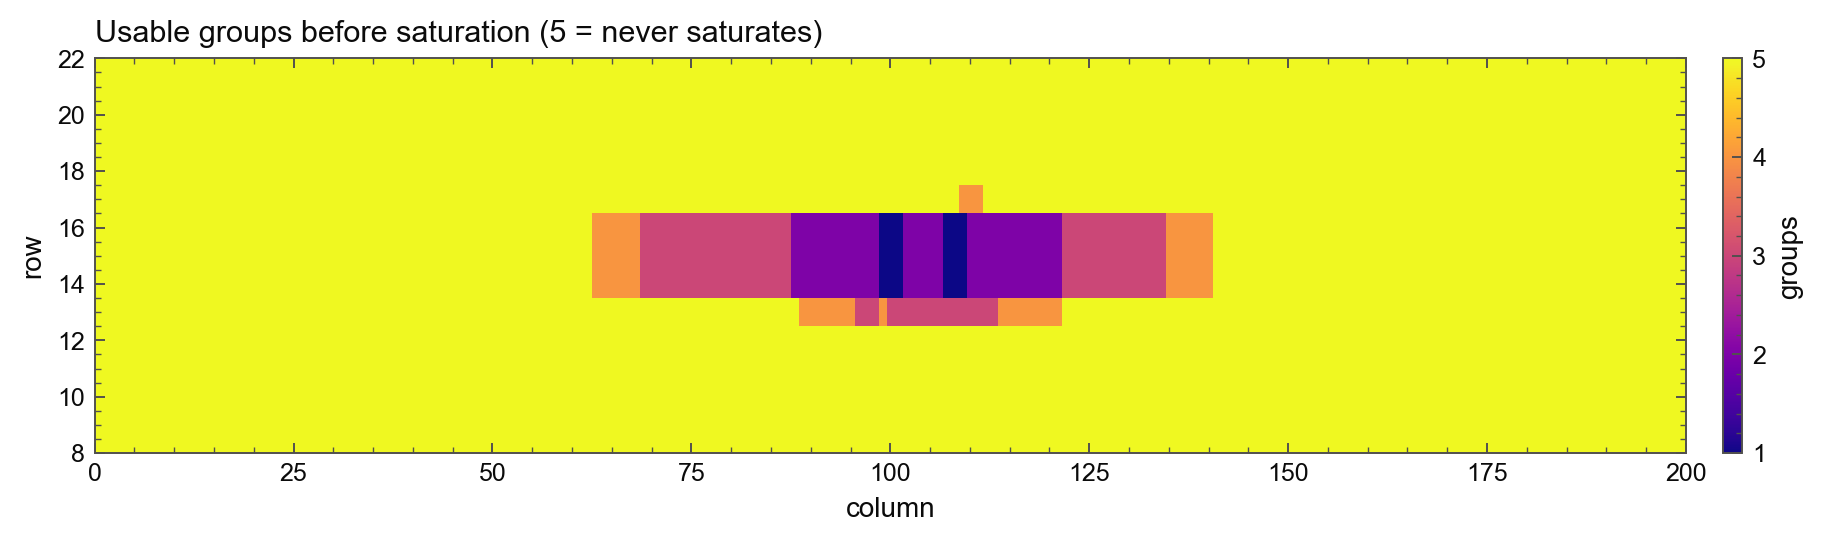

In [3]:
satmap = s1.compute_saturation_map(segments=[0])
ngroups = satmap.max()
print('pixels that saturate:', np.sum(satmap < ngroups))
for g in range(1, ngroups):
    print(f'  usable groups = {g}: {np.sum(satmap == g):4d} pixels')

fig, ax = plt.subplots(figsize=(9, 2.6), layout='constrained')
im = ax.imshow(satmap, origin='lower', aspect='auto', interpolation='none', cmap='plasma')
ax.set_xlim(0, 200); ax.set_ylim(8, 22)
ax.set_xlabel('column'); ax.set_ylabel('row')
ax.set_title('Usable groups before saturation (5 = never saturates)')
fig.colorbar(im, ax=ax, pad=0.01, label='groups');

<div class="alert alert-info">

**Why consistent saturation (tested on these data)**

Without it, 66 pixels changed their number of usable groups from integration
to integration. Their rates then jumped by 3-8%, against a normal scatter of
0.4-1.6%. The worst 10-column bins scattered 2.45 and 3.69 times their
propagated errors; with the step, 1.19 and 1.16 times.

Two related choices:

* jwst's `n_pix_grow_sat=1` (also flag the neighbours of a saturated pixel)
  stays on. Without it the neighbours of the core are 2.5-3 times too bright
  (charge spills from the saturated pixel) and scatter up to 2.8 times their
  errors.
* jwst sets the `SATURATED` flag in the `rateints` DQ of every partially
  saturated pixel, even when it has a valid slope from its first groups.
  jstark does **not** treat that flag as bad. Otherwise 270 pixels at the
  peak of the spectrum would be replaced by interpolation; now only the 18
  with no slope at all (group 0 only) are.

</div>

### 1.2 Running Stage 1

For a test, run the first segment only. Each segment produces a
`*_rateints.fits` file and a `*_stage1diag.npz` file with the diagnostics of
the custom steps.

In [4]:
%%time
rateints = s1.run(segments=[0])
print(rateints)
diag = rdiag.load_stage1_diagnostics(rateints[0].replace('_rateints.fits', '_stage1diag.npz'))
print(list(diag))

Segment 1/4: jw01366004001_04101_00001-seg001_nrs1_uncal.fits


    group_scale          done in    0.3 s


    dq_init              done in    0.4 s


    saturation           done in    3.9 s


    consistent_saturation: 270 pixels, 149166 saturated-group flags added
    consistent_saturation done in    0.6 s


    superbias            done in    0.4 s


... (4 outputs left out)

    ramp_fit             done in   22.9 s


    gain_scale           done in    0.3 s


  -> /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRSPR/tutorial/jw01366004001_04101_00001-seg001_nrs1_rateints.fits  (155.8 s)
['/Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRSPR/tutorial/jw01366004001_04101_00001-seg001_nrs1_rateints.fits']


['consistent_saturation', 'group_bkg', 'temporal_jump', 'trace_mask', 'bkg_mask', 'signal_image']
CPU times: user 2min 6s, sys: 20.3 s, total: 2min 26s
Wall time: 2min 36s


### 1.3 Background region and 1/f noise

NIRSpec reads its detector along columns, one pixel every 10 µs. Slow
drifts of the read-out electronics (1/f noise) therefore add an offset that
is nearly constant along each column of a group and changes from column to
column and from group to group. Since the PRISM disperses along the rows,
each column is one wavelength, and these offsets add correlated noise to
the spectrum. They are removed from every group, before the ramp fit: for
each column, the sigma-clipped median of the pixels outside the trace is
subtracted.

The background pixels come from a mask built on a high-S/N image of the
source (the median over integrations of last minus first group). In each
column, pixels more than 3σ above the background level are trace; the mask
is cleaned of isolated pixels, smoothed along the dispersion and widened by
2 pixels. Everything else that is valid is background.

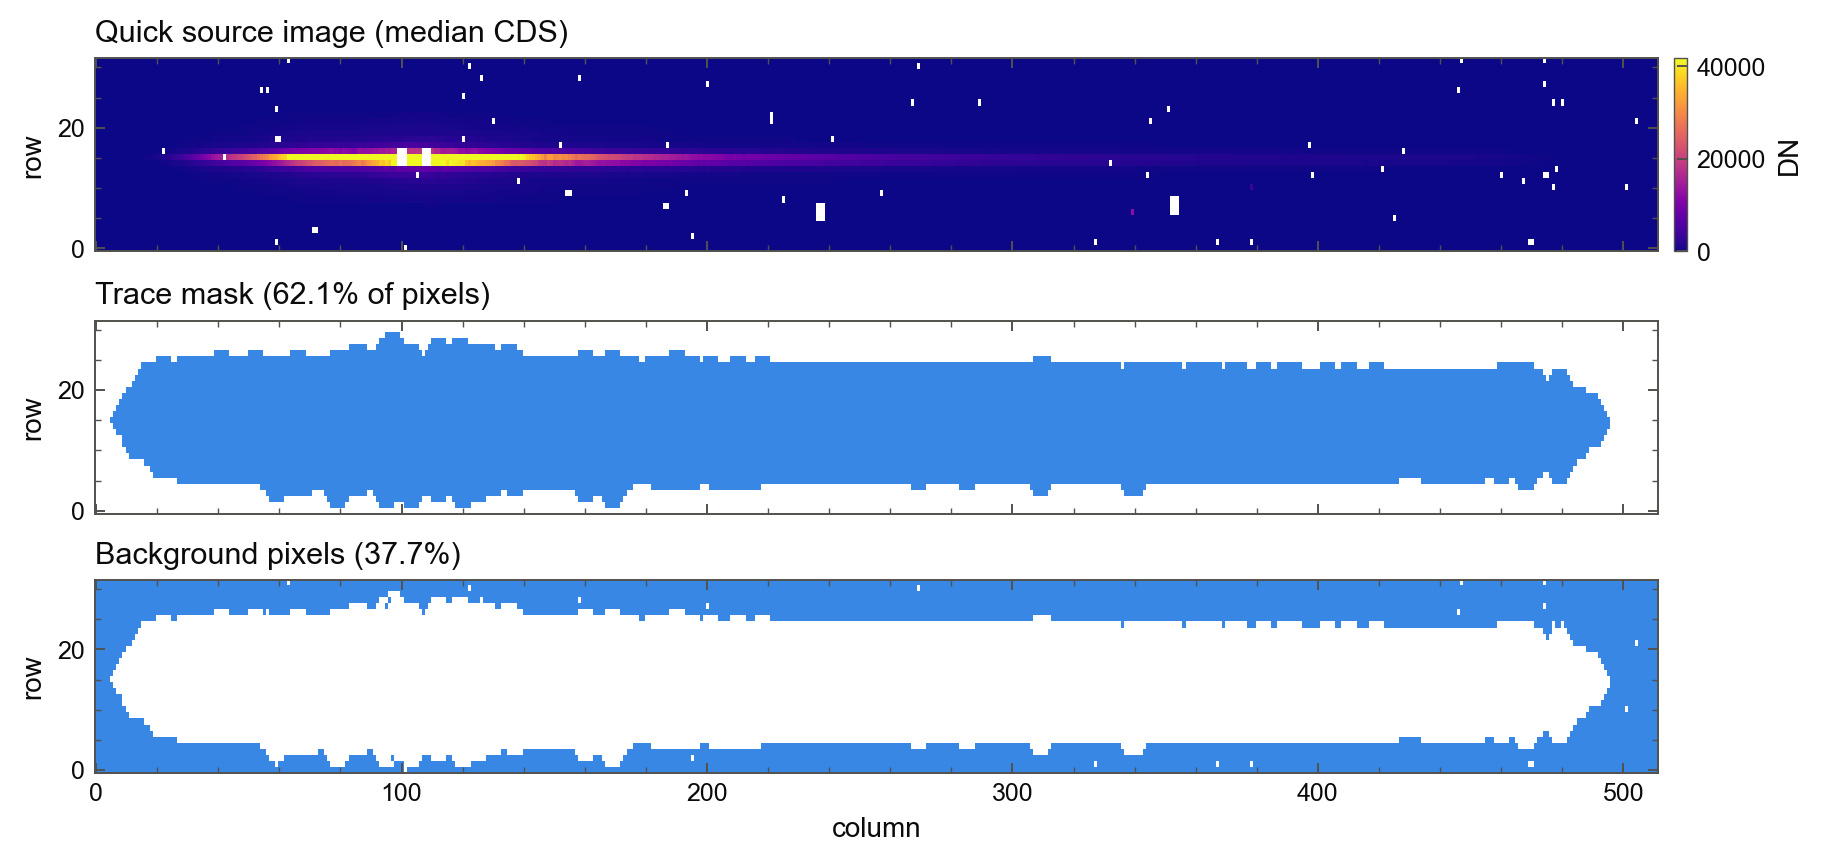

In [5]:
rdiag.plot_masks(s1.signal_image, s1.trace_mask, s1.bkg_mask);

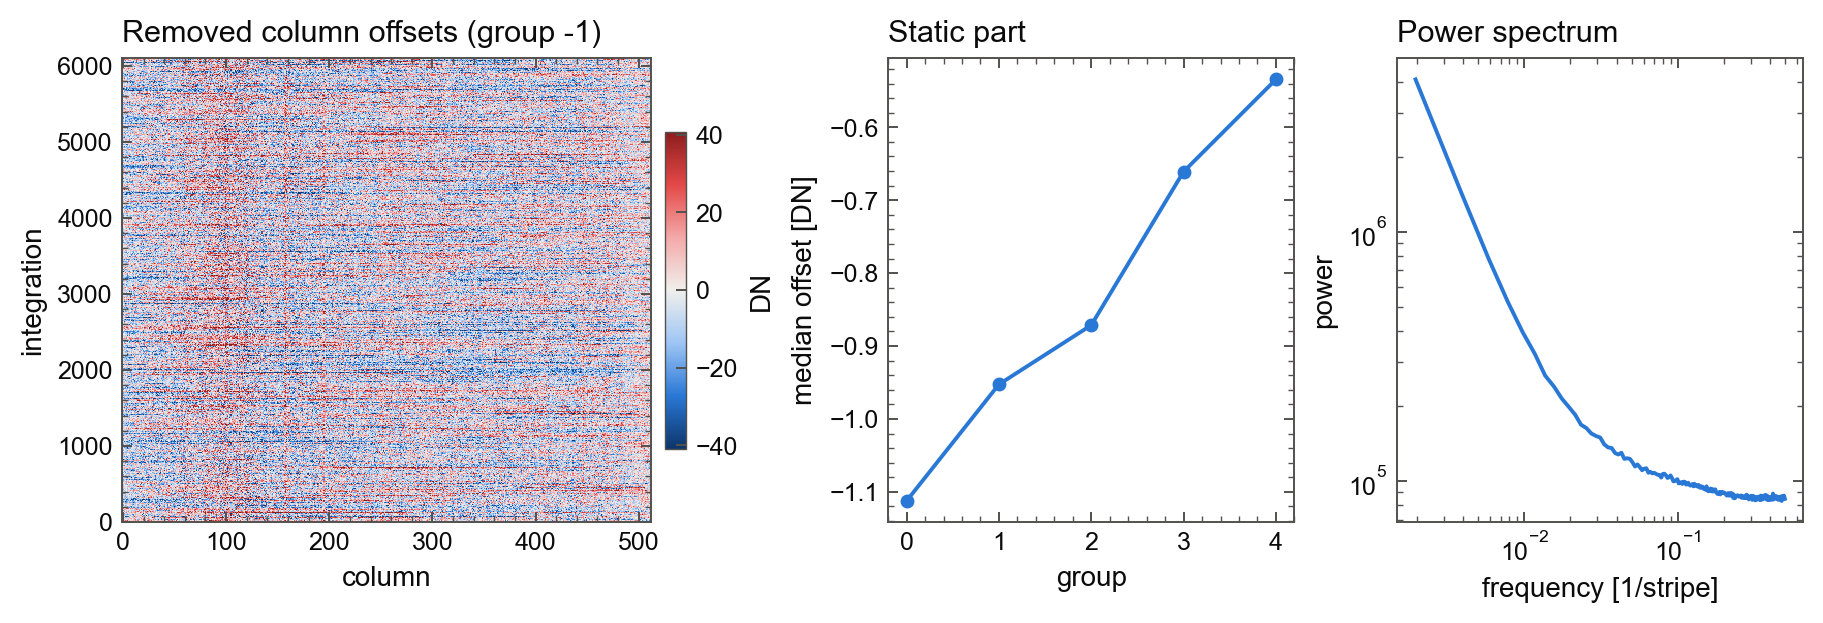

In [6]:
rdiag.plot_group_bkg(diag['group_bkg']['profile'], axis='column');

The left panel shows the column offsets removed from the last group of
every integration; the middle one their average per group (the static
background and bias residual grows with the group); the right one the power
spectrum of the time-variable part.

<div class="alert alert-info">

**Why a column median at the group level**

Group-level 1/f correction methods were compared on the white light of a
NIRSpec/G395H segment (TOI-561, 1525 integrations). The ratio is the
point-to-point scatter divided by the scatter expected from the propagated
errors (1 = white noise).

| `group_bkg` method | White light (ppm) | Ratio | Ratio, 50-column bins |
| --- | --- | --- | --- |
| off | 715 | 4.35 | 1.54 |
| `poly` (order 1 along each column) | 211 | 1.27 | 1.10 |
| `diff` (difference images) | 179 | 1.09 | 1.07 |
| **`median` (default)** | **177** | **1.08** | **1.06** |

The 1/f correction lowers the white-light scatter by a factor of four. A
correction at the group level is better than one on the `rateints`, as
found by other pipelines too (exoTEDRF; Radica et al. 2025, arXiv:2505.05571).

</div>

### 1.4 Cosmic rays at the group level

A cosmic ray adds charge between two groups, so it changes one group
difference of one integration. `temporal_jump` compares every group
difference of a pixel with the running median of the same difference over
the 11 neighbouring integrations, *excluding* the integration being tested,
and flags it above 10σ (σ from the scatter in time, with a read-noise
floor). With fewer than 10 groups the bad difference is replaced by its
running median and the ramp rebuilt, so no group is lost; with 10 or more
groups the jump is flagged and the ramp fit splits the ramp there.

6755 jumps in 6100 integrations


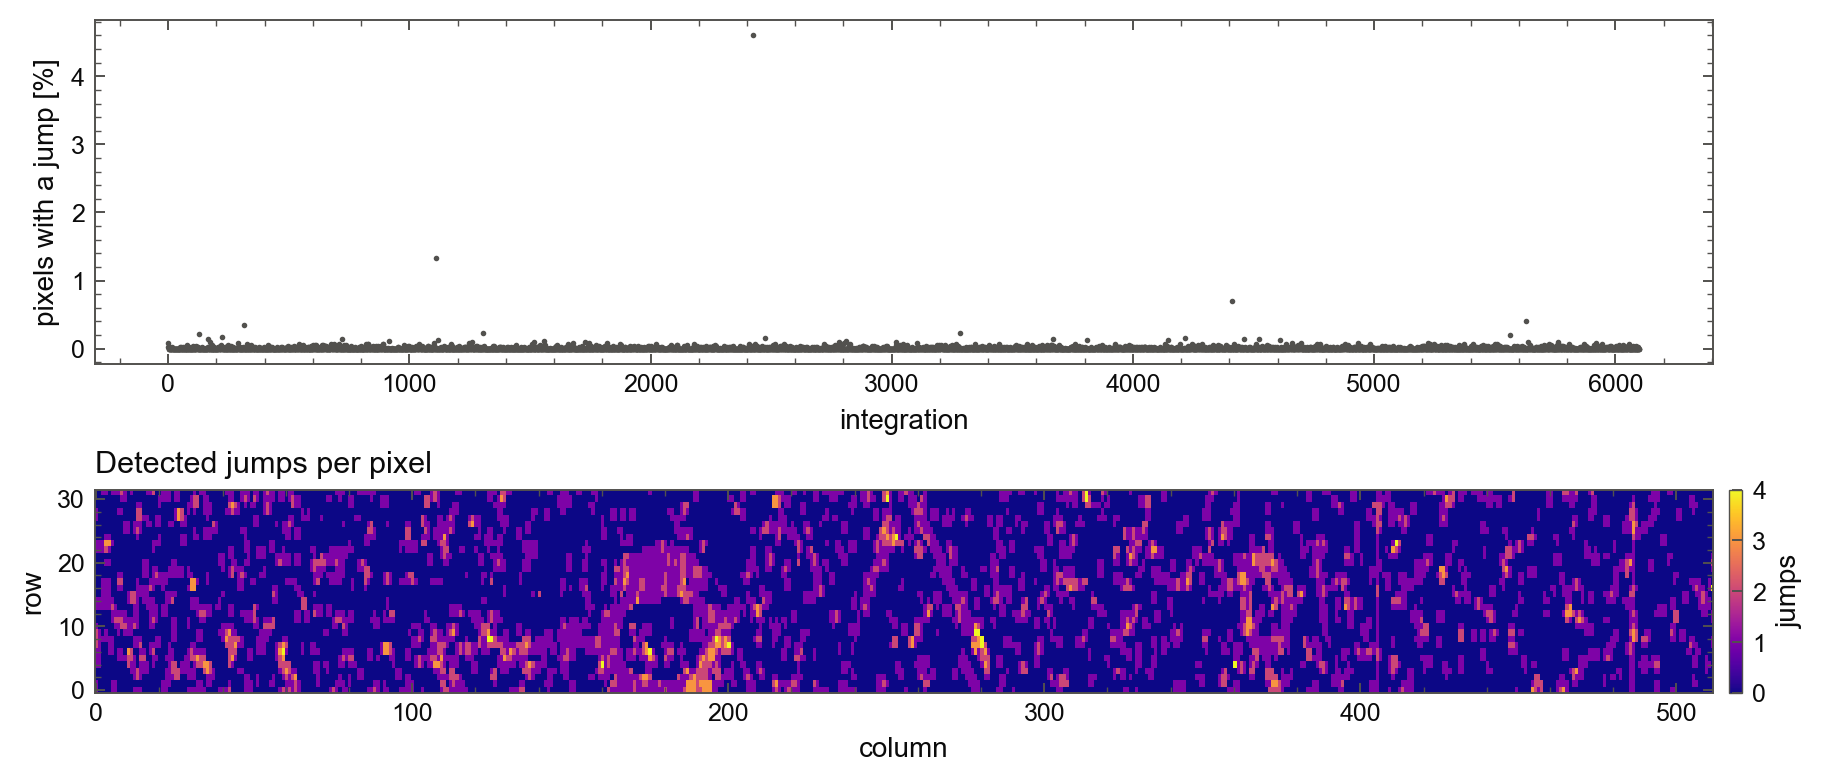

In [7]:
j = diag['temporal_jump']
print(f"{int(j['n_jumps'])} jumps in {len(j['frac_per_int'])} integrations")
rdiag.plot_jumps(j['frac_per_int'], j['jump_count_map']);

<div class="alert alert-info">

**Why leave-one-out**

On a synthetic 10-group ramp with a 3000 DN hit between groups 3 and 4, the
rate without a cosmic ray is 44.38 ± 2.48 DN/s, undetected 391 DN/s,
flagged 42.87 ± 2.81 and replaced 44.15 ± 2.48 DN/s. Including the tested
integration in its own running median underestimated the noise by about
20%, so a 5σ threshold acted like a 4σ one: false detections on clean data
fell from 105 to 8 when it was excluded.

</div>

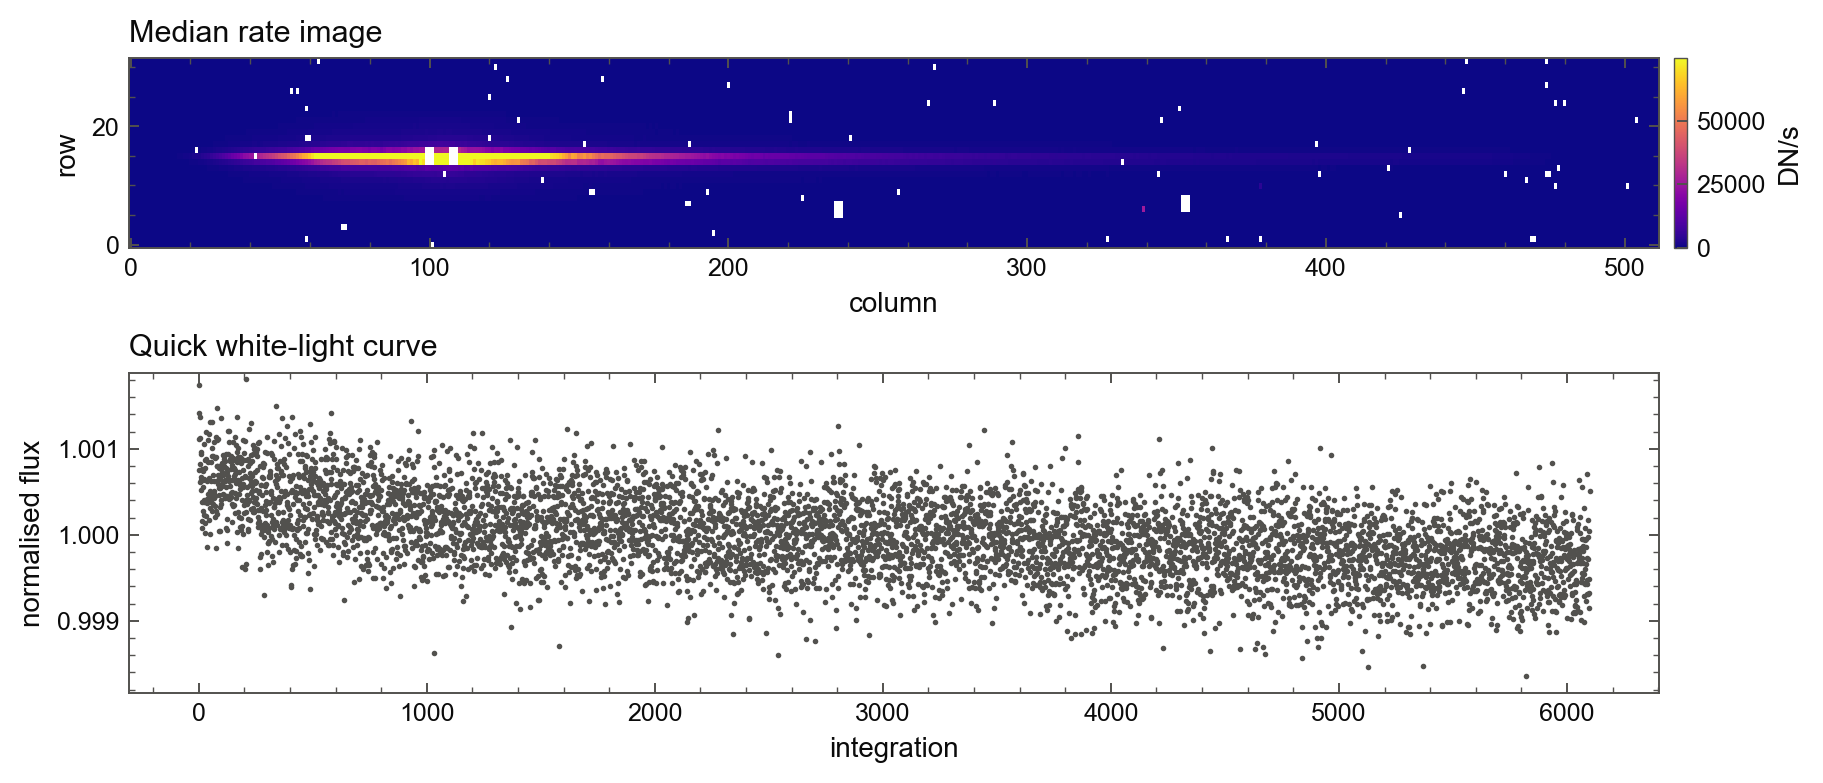

In [8]:
rdiag.plot_rateints(rateints[0], trace_mask=s1.trace_mask);

## 2. Stage 2: wavelength map

jstark does not flat-field or flux-calibrate the data for time-series work:
it only needs the wavelength of every pixel. `Stage2` evaluates the WCS
(`assign_wcs`) on the full subarray, so the map has the geometry of the
data.

Wavelength map (32, 512): 0.468-5.716 micron
Saved wavelength map to /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRSPR/tutorial/jw01366004001_04101_00001_nrs1_wavelength.fits
row 16: 0.47 - 5.71 micron


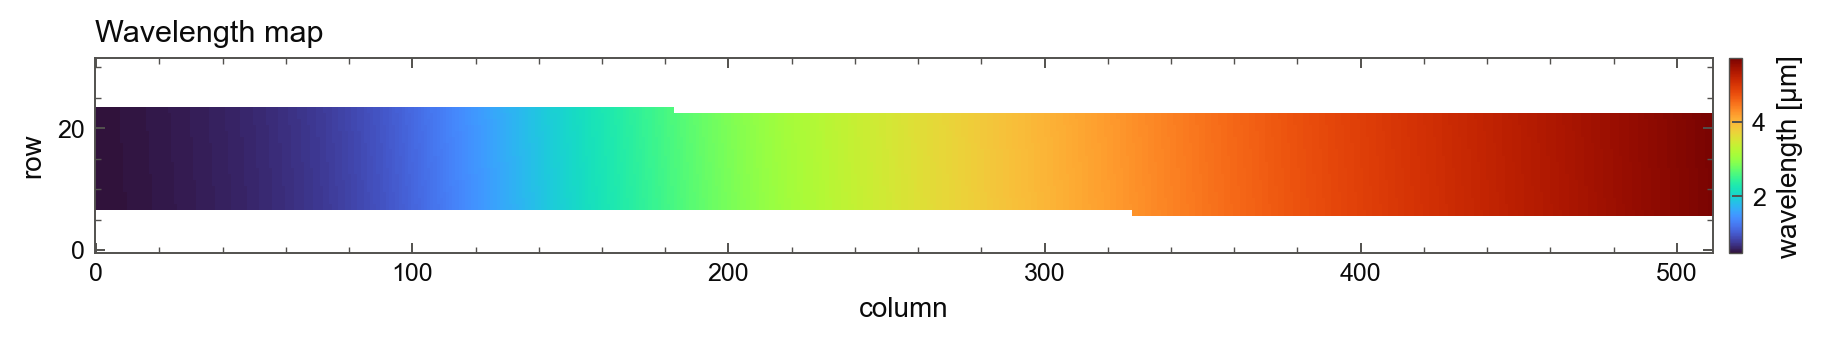

In [9]:
wfile = Stage2(TUT).run()['wavelength']
wave = fits.getdata(wfile, 'WAVELENGTH')
rdiag.plot_wavelength(wave)
print(f'row 16: {np.nanmin(wave[16]):.2f} - {np.nanmax(wave[16]):.2f} micron')

## 3. Cleaning: bad pixels and cosmic rays

`ExposureCleaner` cleans the exposure segment by segment, without ever
stitching the segments into one cube:

1. **Pass 1** reads every segment once and builds exposure-wide maps: the
   median frame, the per-pixel scatter in time, persistent bad pixels (bad
   DQ flags in most integrations, hot, cold and noisy pixels), and the noise
   level used for cosmic-ray detection.
2. **Pass 2** cleans each segment, padded with 6 integrations from its
   neighbours so that the running medians are the same as in a stitched
   cube: errors are repaired, transient outliers found in time, transient
   pixels replaced by their running median in time, and persistent bad
   pixels interpolated along the dispersion.

It writes one `*_cleaned.fits` per segment and a small
`<exposure>_cleaninfo.fits`, the input of the extraction.

ExposureCleaner: NIRSpec/PRISM | jw01366004001_04101_00001_nrs1 | 1 segment(s), 6100 integrations


  pass 1: segment 1/1 read
compute_global: 101 bad pixels from DQ, 60 hot/noisy pixels; trace mask 63.8% of pixels


  segment 1/1: 7805 transient flags (1.3 per integration) -> jw01366004001_04101_00001-seg001_nrs1_cleaned.fits
Saved exposure info to /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRSPR/tutorial/jw01366004001_04101_00001_nrs1_cleaninfo.fits


NIRSpec/PRISM: (6100, 32, 512); persistent bad pixels: 161 (0.98%); transient flags: 7805 (0.0078%, 1.3 per integration)


CPU times: user 39.7 s, sys: 2.22 s, total: 41.9 s
Wall time: 43 s


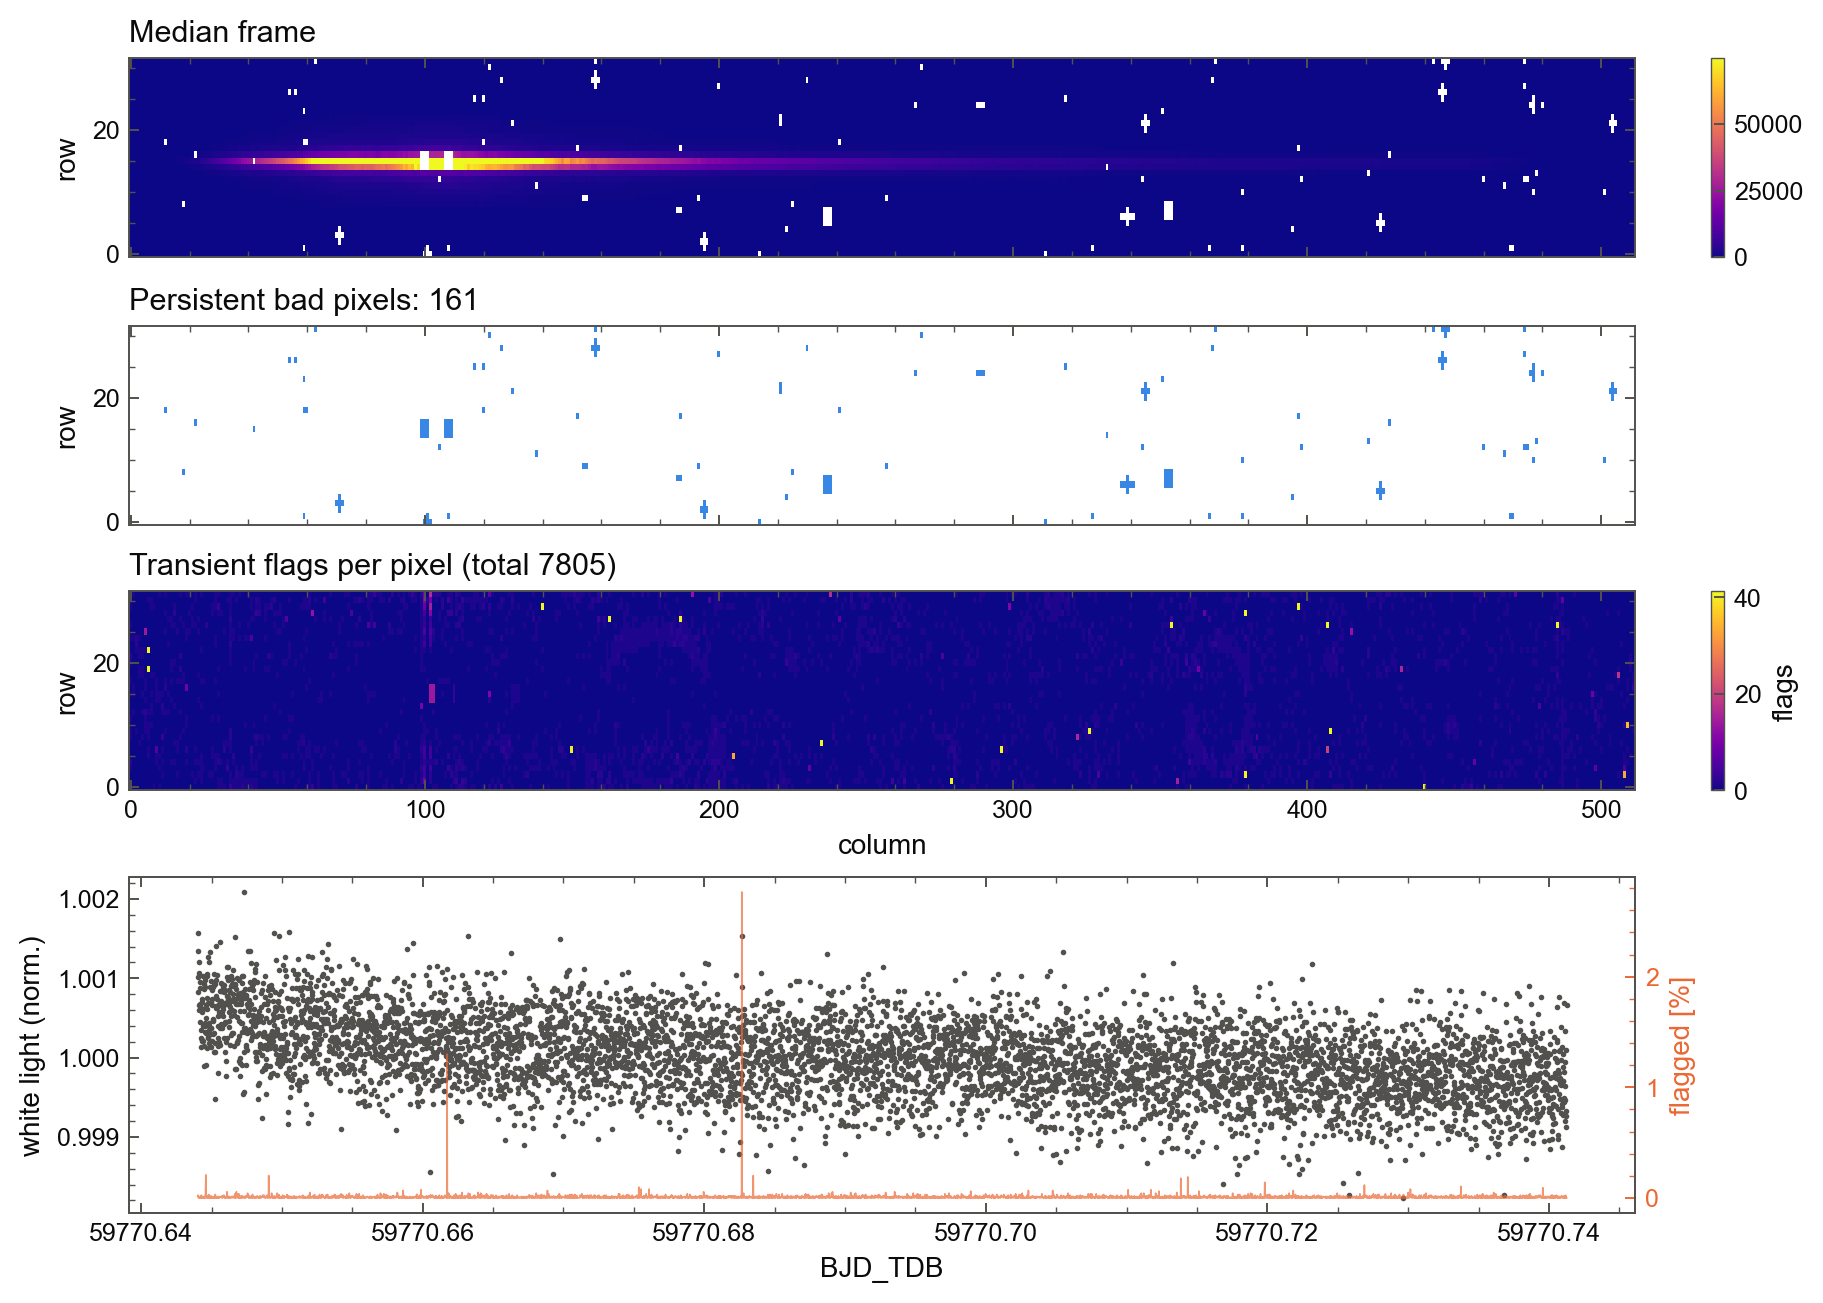

In [10]:
%%time
info = ExposureCleaner(TUT, wavelength=wfile).run()
cc = ExposureCleaner.load(info).load_segment(0)
cc.summary()
rdiag.plot_cleaning(cc);

<div class="alert alert-info">

**Why exposure-wide statistics**

* Hot pixels are found against the median of their *neighbours, excluding
  the pixel itself*: with the pixel included, the median absorbed it and
  5.6% of the detector was flagged.
* The noise of every pixel for the cosmic-ray test comes from the whole
  exposure. Estimated per segment it was noisier and gave three times more
  false flags (323 against 5 on clean data).

</div>

## 4. Spectral extraction

`SpectralExtractor` measures the trace, fits a model of the spatial profile
(the PSF) to all integrations and extracts every integration optimally with
it. It works chunk by chunk, so the exposure is never in memory at once.
`show()` lists the parameters of each step.

In [11]:
ex = SpectralExtractor(info)
ex.show()

SpectralExtractor: NIRSpec/PRISM | jw01366004001_04101_00001_nrs1 | 1 segment(s), 6100 integrations | orders [1]
NIRSpec/PRISM | orders [1]
  columns     columns=None, wavelength_range=None, snr_min=5.0, min_good_frac=0.5, gap=5
  trace       halfwidth=None, nknots=8, clip=3.0, reference=None, ref_order=1
  background  method=median, inner=8.0, outer=None, nsigma=3.0, maxiters=3, poly_order=1, min_pixels=4
  psf         halfwidth=7.0, oversample=2.0, knot_col=20, smooth=cv, clip=6.0, init_ints=200, ints=all, second_pass=False, pixel_correction=True, cv=phase
  extract     method=optimal, aperture=5.0, variance=mean, reject=6.0, reject_iters=3, reject_mode=temporal, fit_background=False, refine_shift=2, joint_iters=3, max_maskfrac=0.98, min_groups=2, cov_scale=1.0, saturated_box=False


  order 1: columns 14-483, 0.502-5.518 um; trace rows 14.59-14.95; centroid rms about the fit 0.008 px


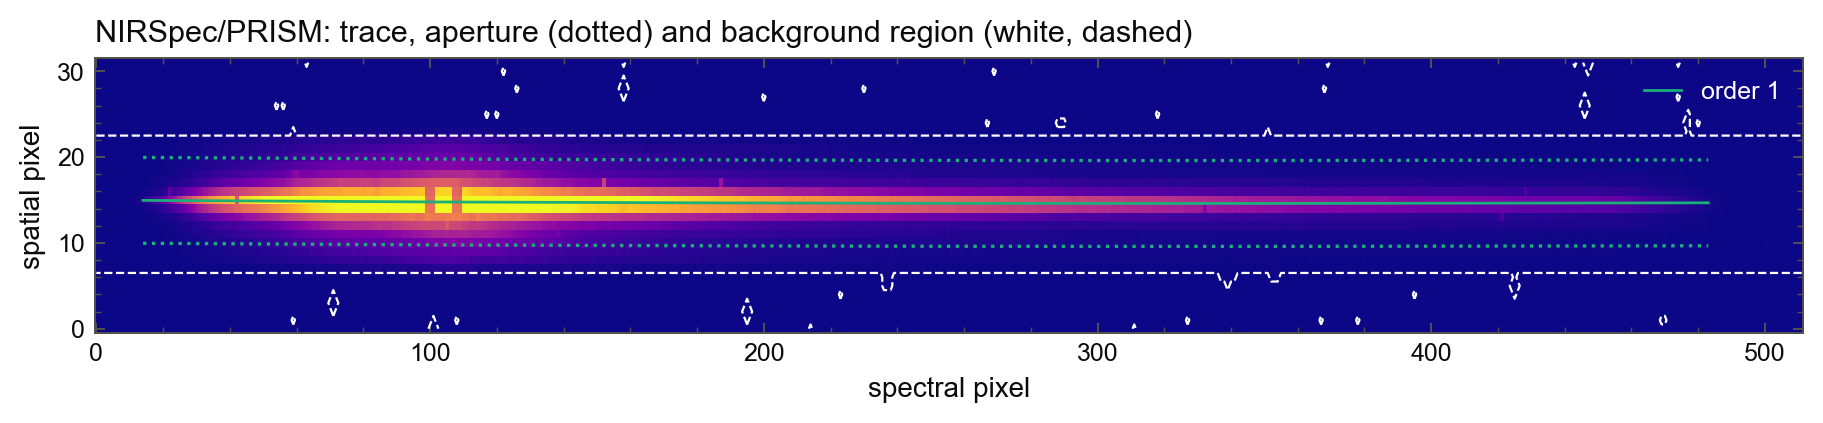

In [12]:
ex.find_trace()
xdiag.plot_trace(ex);

### 4.1 The PSF model

The profile is a cubic tensor-product spline $S(u, x)$ of the offset from
the trace $u$ and the column $x$, fitted to the pixel values divided by a
noise-free estimate of each column's flux. The least-squares sums are
accumulated chunk by chunk over all integrations, so the result is the same
as a fit to the stitched exposure. Smoothness penalties suppress
oscillations of the spline where the data do not constrain it; their
strengths are chosen by cross-validation (below).

The model of a pixel is $f_x(t)\,P(u, x)\,Q_p$: the column flux, the
profile, and a **pixel-response factor** $Q_p$ fitted in the same pass.

In [13]:
%%time
ex.fit_psf()

  order 1: first PSF from 200 integrations; residual scale 1.26 sigma; 0.000% of pixels rejected


  order 1: PSF pass 1: 39795136 pixels from 6100 integrations, 744 coefficients, smoothing (u, x) = (2e-04, 2e+00), reduced chi2 12.846, rejected 0.000%
  pixel-response map: 6524 pixels, rms 0.0613
fit_psf done in 26 s
CPU times: user 28.7 s, sys: 13.8 s, total: 42.5 s
Wall time: 26.4 s


{1: <jstark.extraction.psf.SplinePSF at 0x704fb15550>}

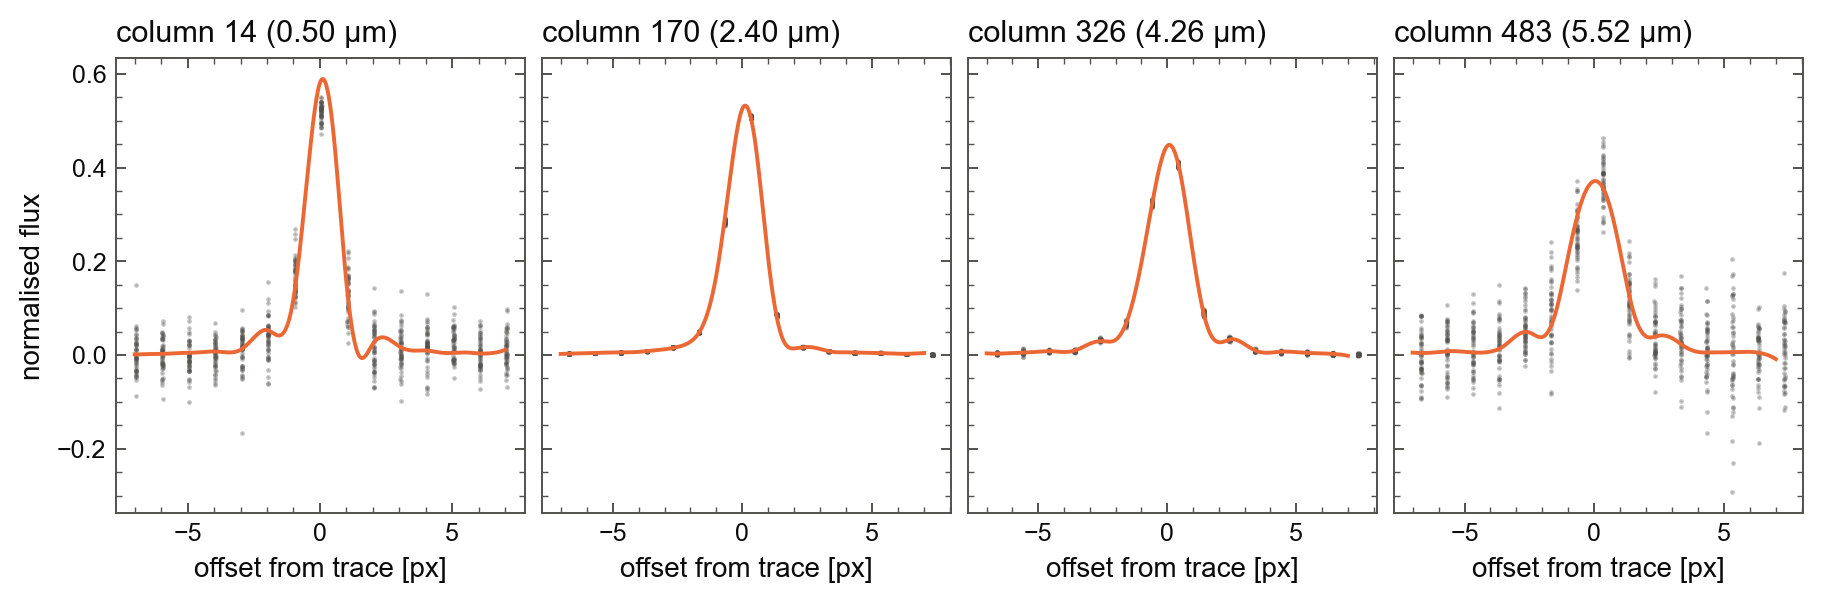

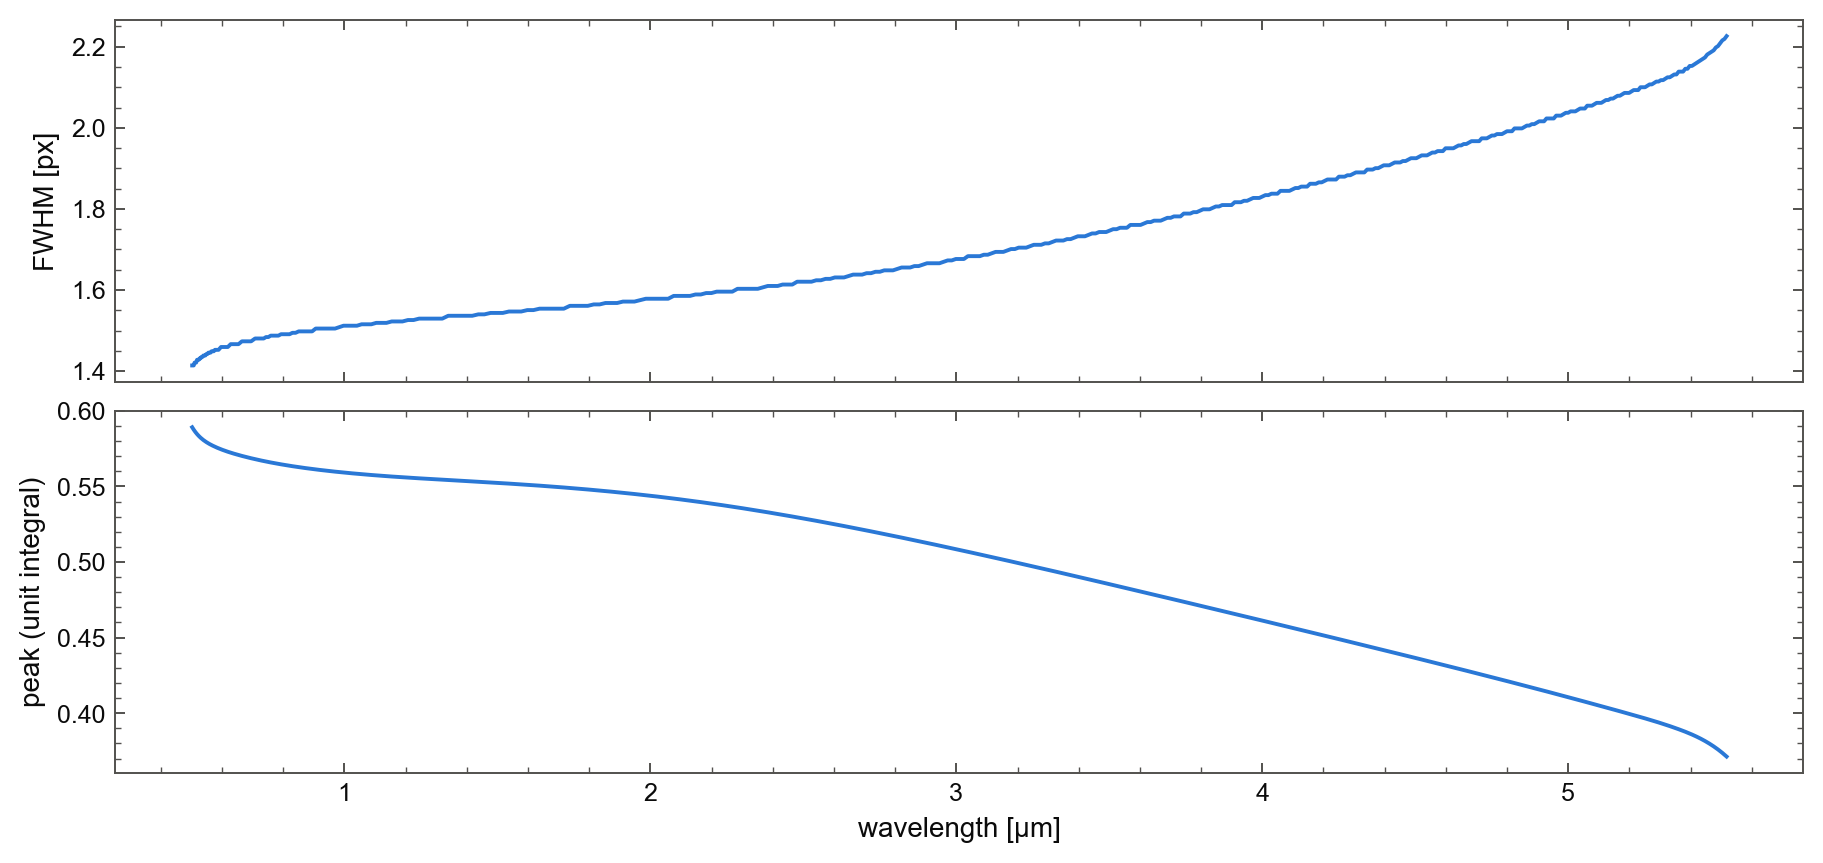

In [14]:
xdiag.plot_psf(ex);
xdiag.plot_psf_width(ex);

<div class="alert alert-info">

**Why the PSF smoothing is cross-validated between sub-pixel phases**

The spline has a knot every half pixel in $u$, but in a short stretch of
columns the trace samples only part of a pixel's phases. With finely
spaced column knots the profile developed negative lobes (down to −0.6 of
its peak) where no data constrained it, and the extraction fell apart
(1195 instead of 167 ppm on the same 400 integrations of a G395H segment).

The penalties are therefore chosen by how well a profile fitted to the
pixels with one half of the sub-pixel phases (fractional offset from the
trace below 0.5) predicts the other half. That is exactly the interpolation
needed when the trace moves. Two other schemes failed: even/odd
integrations sample the same phases (so the weakest smoothing always
"won"), and held-out blocks of columns over-smoothed along the dispersion
(PRISM: 478 ppm against 350-369 ppm). With phase cross-validation, every
knot setting tried on G395H gave 175 ± 1 ppm.

</div>

rms of Q on bright pixels: 3.63% (1831 pixels); on all measured pixels: 6.13%


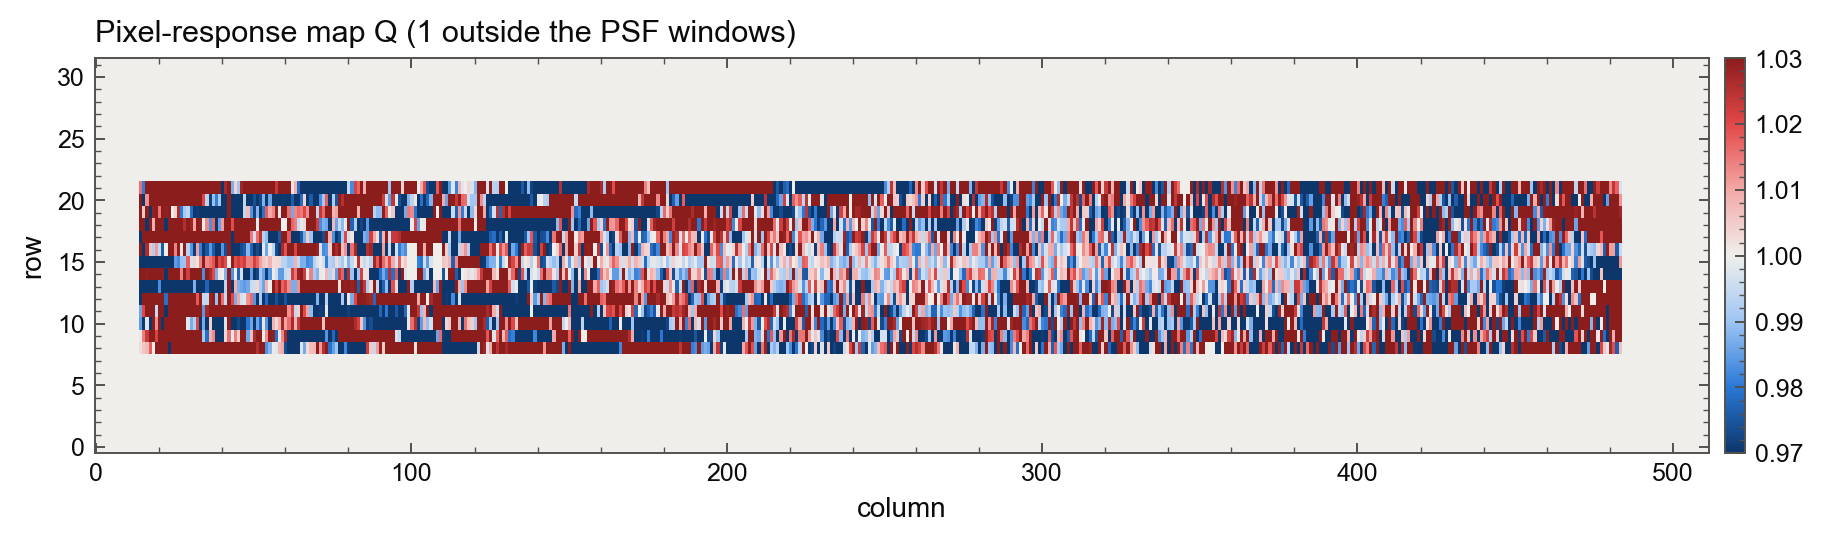

In [15]:
fig, ax = plt.subplots(figsize=(9, 2.6), layout='constrained')
im = ax.imshow(ex.qmap, origin='lower', aspect='auto', interpolation='none',
               cmap='jstark_div', vmin=0.97, vmax=1.03)
ax.set_title('Pixel-response map Q (1 outside the PSF windows)')
ax.set_xlabel('column'); ax.set_ylabel('row')
fig.colorbar(im, ax=ax, pad=0.01)
med = ex.src.median
bright = (ex.qmap != 1) & (med > 0.1 * np.nanmax(med, axis=0))   # within 10% of each column's peak
print(f'rms of Q on bright pixels: {np.std(ex.qmap[bright]) * 100:.2f}% ({bright.sum()} pixels); '
      f'on all measured pixels: {np.std(ex.qmap[ex.qmap != 1]) * 100:.2f}%');

<div class="alert alert-info">

**Why a pixel-response map instead of a flat field**

The data are not flat-fielded (the CRDS flat field is known to *add*
light-curve scatter). In the first version of the extraction, the optimal
spectrum of a G395H segment was *worse* than a plain box sum (187.5 against
177.2 ppm), because the static ratio between data and model had 2.2% rms on
bright pixels, perfectly reproduced between even and odd integrations: the
pixel sensitivities. No smooth profile can fit that, and bright core pixels
were rejected as outliers in some integrations and kept in others.

With $Q$ in the model, the χ² per pixel fell from 1.51 to 0.77, the >6σ
pixels from 31 to 0.005 per integration, and the optimal extraction became
the best estimate (176.7 ppm, ratio 1.058). $Q$ is never divided into the
data: it only enters the weights. In the faint wings each factor is
shrunk towards 1 according to its precision, and those pixels carry little
weight in the extraction. It also matters when the trace moves:
without it the optimal flux is a profile-weighted mean of the pixel
sensitivities, which changes with the trace position.

</div>

### 4.2 Extraction

Each integration is extracted with the optimal weights $e\,P Q / V$:
fractional aperture weights $e$ (so the flux changes smoothly when the trace
moves), the time-averaged variance of each pixel $V$, and masked pixels left
out. The trace offset $dy(t)$ and a width change $ds(t)$ of every
integration are fitted at the same time and saved as regressors.

Remaining outliers are rejected *temporally*: a pixel is rejected only if
its residual differs from its own median residual over the chunk. A static
misfit then never makes a pixel switch between kept and rejected, the same
switching problem as with saturation.

  order 1: 6 column(s) with < 2 usable groups in the aperture set to NaN: columns [99, 100, 101, 107, 108, 109] (1.088-1.263 um)


  segment 1/1: 6100 integrations; order 1: 0.0 rejected px/int, dy rms 4.4 mpx
extraction done in 61 s


Saved spectra to /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRSPR/tutorial/jw01366004001_04101_00001_nrs1_spectra.fits
CPU times: user 47.8 s, sys: 16.5 s, total: 1min 4s
Wall time: 1min 1s


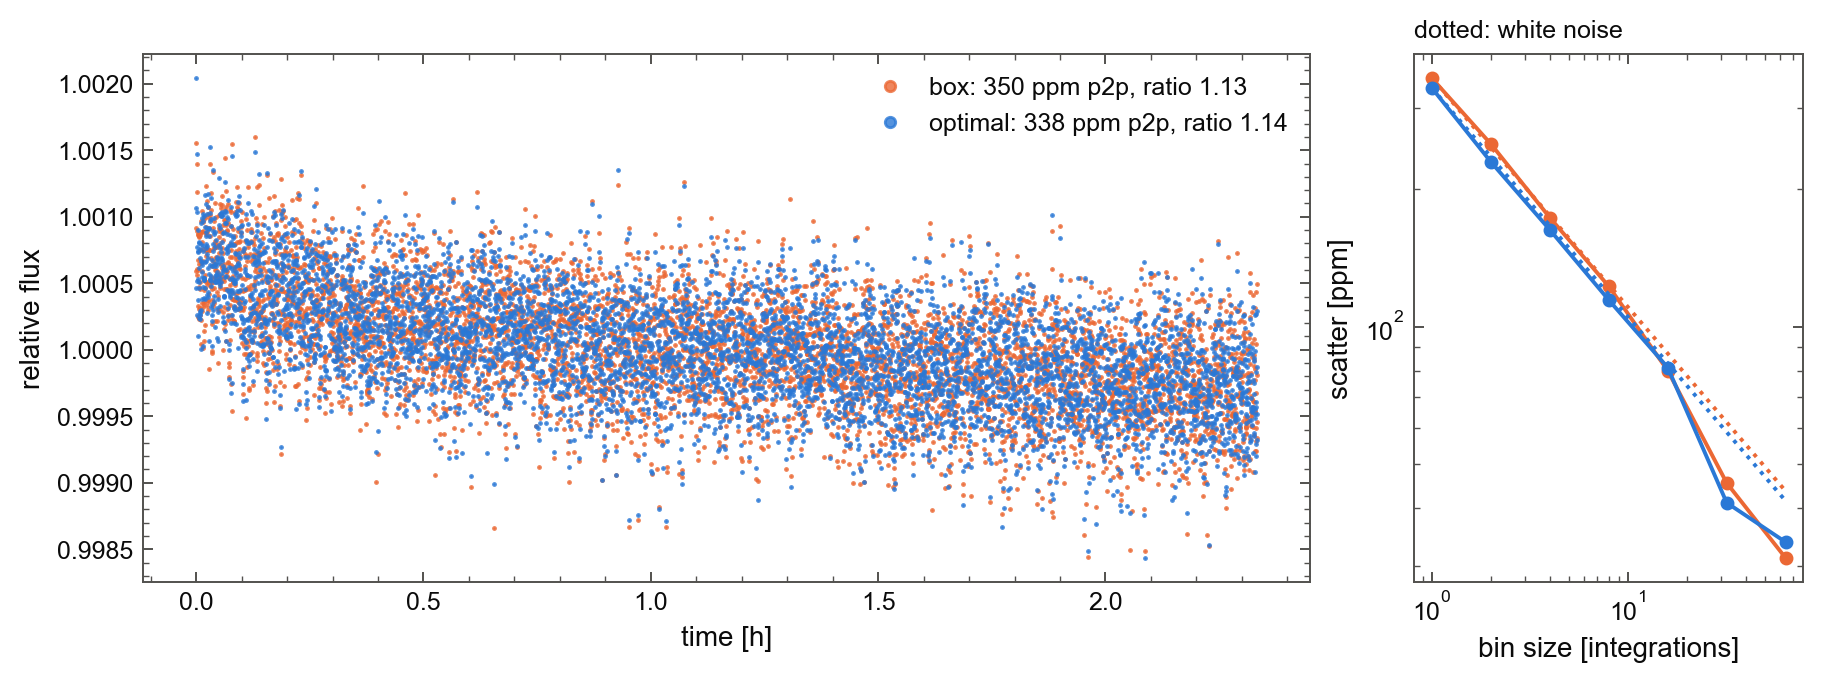

In [16]:
%%time
spec1 = ex.run()
xdiag.plot_white_light(spec1);

### 4.3 The saturated columns

`SATGRP` gives, for every column, the fewest usable groups of any pixel in
the aperture. Columns whose core keeps only group 0 (fewer than
`min_groups=2` groups) are set to NaN: their flux would come from the wings
alone.

detector columns set to NaN: [ 99 100 101 107 108 109] at [1.088 1.104 1.12  1.226 1.244 1.263] micron


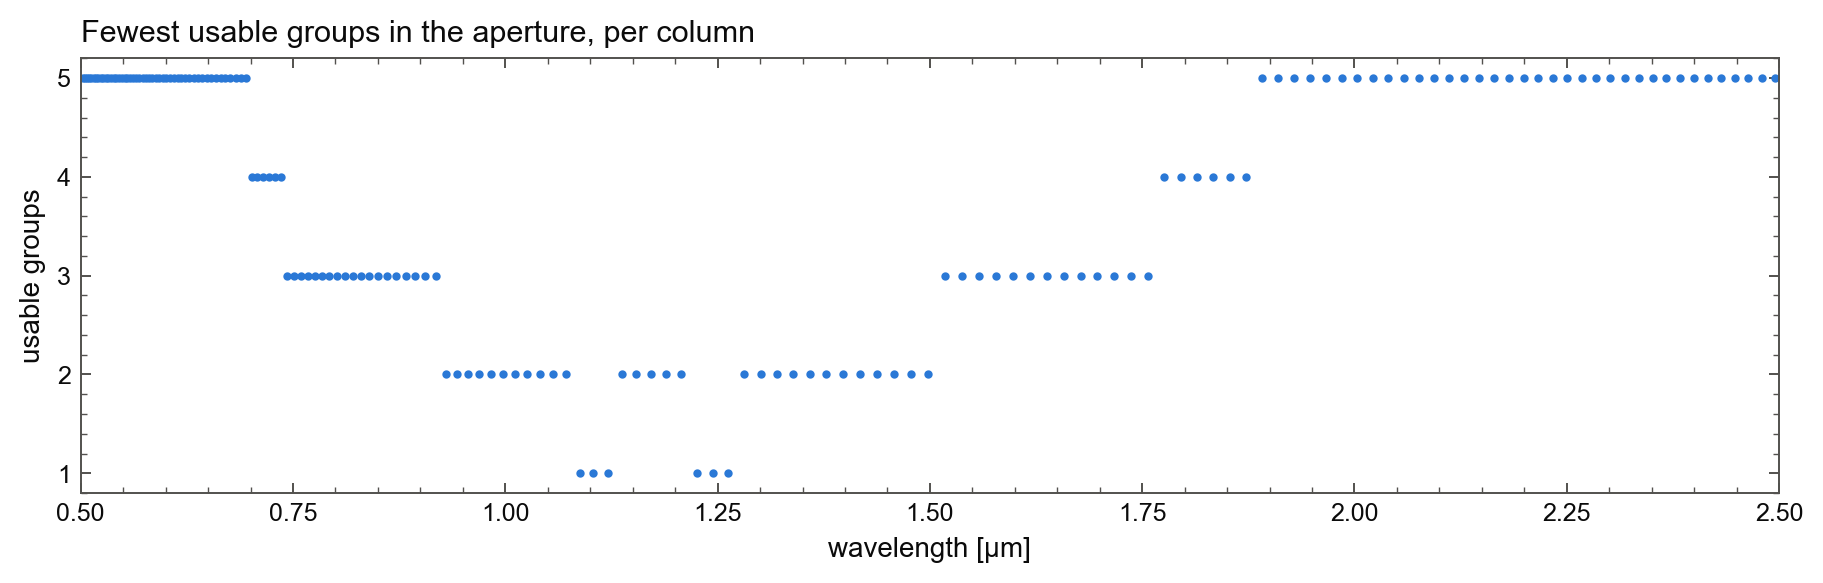

In [17]:
o = 1
lam, satgrp = spec1.wavelength[o], spec1.satgrp[o]
fig, ax = plt.subplots(figsize=(9, 2.8), layout='constrained')
ax.plot(lam, satgrp, '.', color='C0', ms=4)
ax.set_xlabel('wavelength [µm]'); ax.set_ylabel('usable groups')
ax.set_xlim(0.5, 2.5)
ax.set_title('Fewest usable groups in the aperture, per column')
nan_cols = np.all(~np.isfinite(spec1.flux[o]), axis=0)
print('detector columns set to NaN:', spec1.cols[o][nan_cols], 'at', np.round(lam[nan_cols], 3), 'micron')

The partially saturated columns (2-4 usable groups, 0.70-1.87 µm) are kept,
but their depths need care. Section 7 shows why and what the option
`saturated_box` does about it.

## 5. The full exposure

The full exposure is processed with the same code, without `segments=`.
On the machine used here (14 cores, 48 GB of memory; ramp fitting
with the default of half the cores) this took 16 minutes: Stage 1 9 min
(saturation pre-pass included), cleaning 2.3 min, extraction 5 min (the PSF
fit over all 21,500 integrations takes 78 s). The products take 11 GB.

In [18]:
if RUN_FULL:
    s1 = Stage1(DATA, outdir=FULL)
    s1.set('ramp_fit', maximum_cores='4')
    s1.run()                                       # saturation map from all segments
    wfile_full = Stage2(FULL).run()['wavelength']
    info_full = ExposureCleaner(FULL, wavelength=wfile_full).run()
    exf = SpectralExtractor(info_full)
    exf.find_trace()
    exf.fit_psf()
    exf.run()

(21500, 470) (integrations, columns)


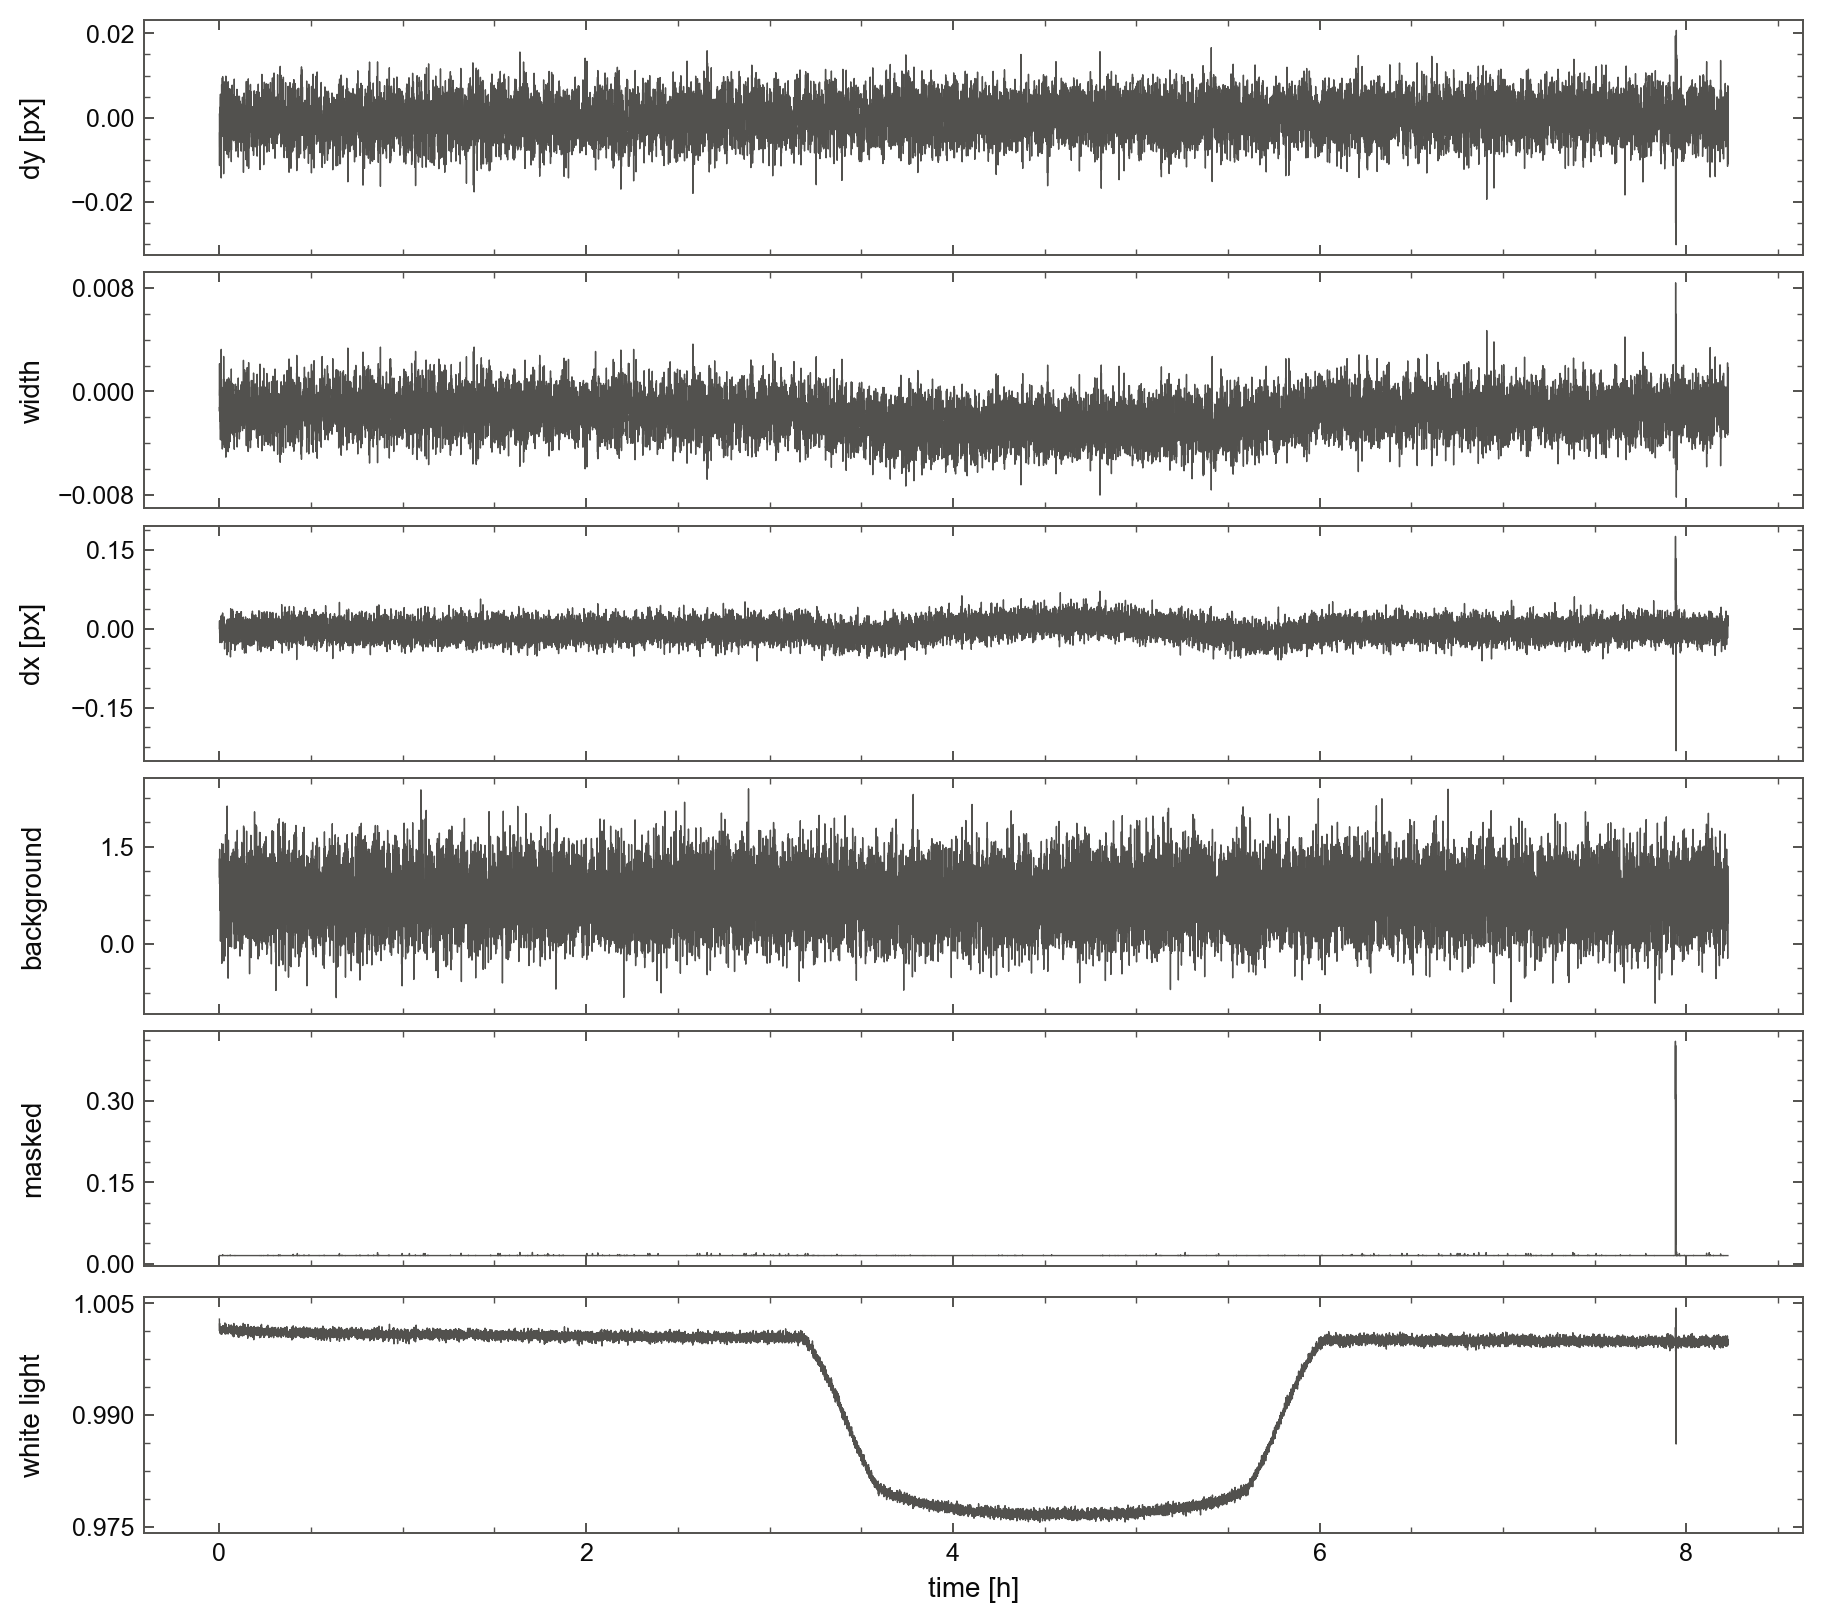

In [19]:
spec = Spectra(os.path.join(FULL, f'{ROOT}_spectra.fits'))
print(spec.flux[1].shape, '(integrations, columns)')
xdiag.plot_regressors(spec);

Two things stand out in the regressors:

* At integration 20,750 (7.9 h) the high-gain antenna of JWST moved, which
  shifted the trace (`dy`, `dx`) and changed its width (`ds`). Rustamkulov
  et al. (2023) excluded integrations 20,750-20,765, and so do we.
* `ds` decreases during the transit: the PSF narrows when the flux drops,
  because of the brighter-fatter effect (charge in bright pixels pushes new
  charge into the neighbours). `dx` shows a small transit-shaped signal too.
  **`ds` and `dx` must therefore not be used as regressors in transit
  fits**: they would absorb part of the transit.

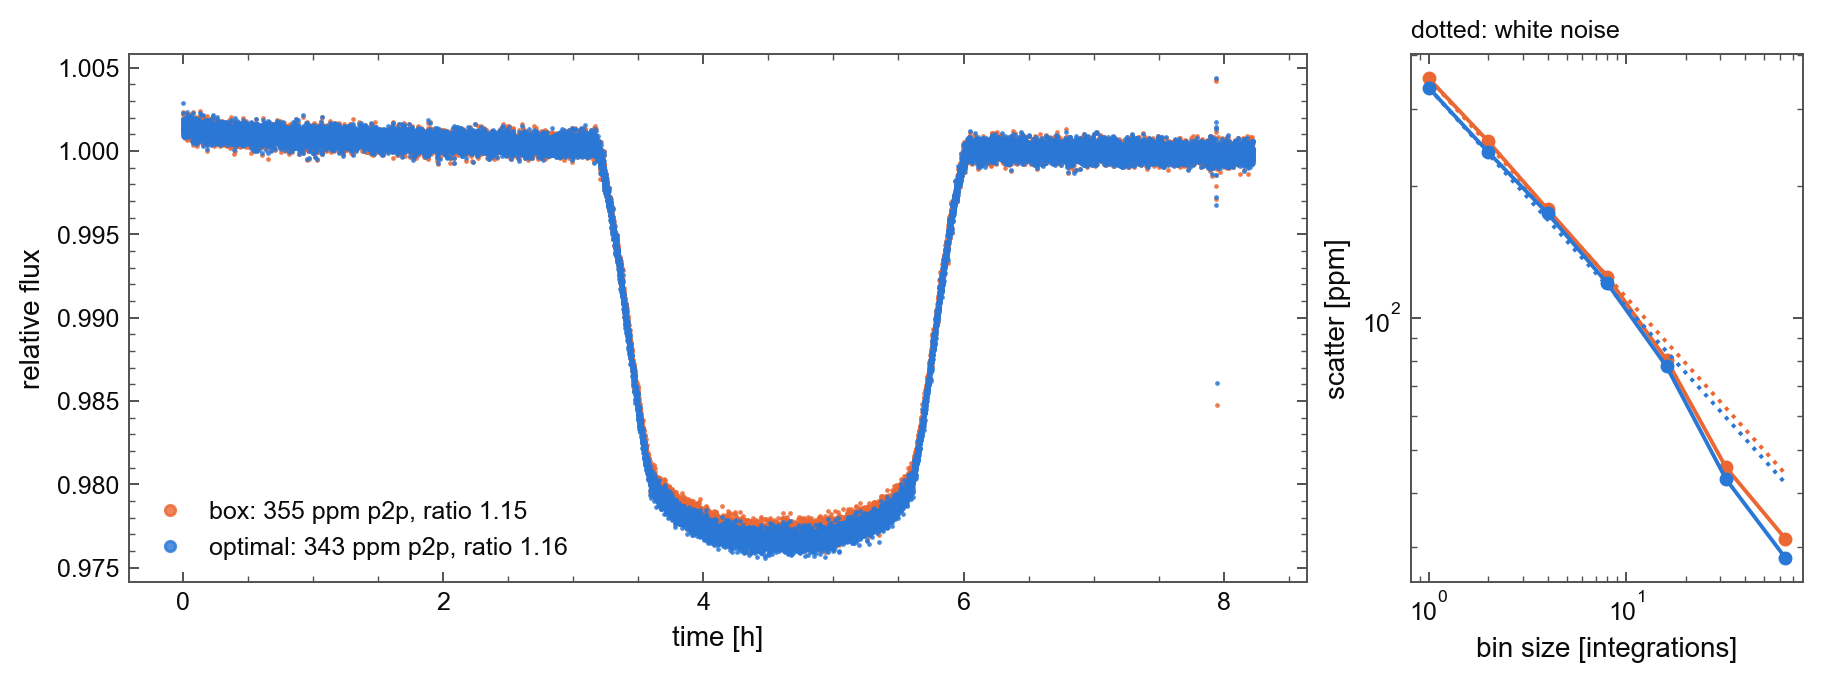

In [20]:
xdiag.plot_white_light(spec);

<div class="alert alert-info">

**Comparison with the published light curves**

Against the ERS benchmark light curves (Carter & May et al. 2024: the
FIREFLy reduction, 147 bins, same time stamps), out of transit:

| Quantity | jstark | published |
| --- | --- | --- |
| White light 2-5.35 µm, scatter per integration | 471 ppm (1.08 × errors) | 487 ppm |
| same, 10-integration bins | 166 ppm | 174 ppm |
| Red noise β at 64 / 256 integrations | 1.12 / 1.27 | 1.12 / 1.23 |
| 147 bins above 2.3 µm: median scatter ratio jstark / published | 0.997 | |

There are no steps at the segment boundaries (+2 ± 13, +22 ± 14 and
+13 ± 13 ppm), so treating the segments separately costs nothing.

</div>

## 6. White-light fit

`LightCurves.from_spectra` reads the spectra with all regressors. The white
light is the **sum** of the columns from 2 to 5.35 µm (outside the saturated
region). The fit uses juliet with dynamic nested sampling: a transit with
quadratic limb darkening (q1, q2 free), a linear trend in time, the trace
offset `dy`, and one exponential ramp for the settling at the start of the
visit, so no integrations are discarded.

In [21]:
white_dir = os.path.join(FULL, 'fits', 'white_2.0-5.35')
if RUN_FULL:
    lc = LightCurves.from_spectra(spec.fname, name='PRISM')
    lc = lc.select_channels(wave_range=(2.0, 5.35)).exclude(ints=[(20750, 20766)])
    pri = {'P_p1': ('fixed', 4.0552941), 't0_p1': ('normal', [2459771.335647, 0.002]),
           'p_p1': ('uniform', [0.1, 0.2]), 'b_p1': ('uniform', [0., 1.]),
           'a_p1': ('uniform', [5., 20.]), 'ecc_p1': ('fixed', 0.), 'omega_p1': ('fixed', 90.),
           'q1_PRISM': ('uniform', [0., 1.]), 'q2_PRISM': ('uniform', [0., 1.])}
    fit = BroadbandFit({'PRISM': lc}, priors=pri, out_folder=white_dir,
                       linear=['time', 'dy'], ramp=1)
    fit.fit(nthreads=8)                   # 13 min
fit = BroadbandFit.load(white_dir)
fit.summary()

Detected dynamic_dynesty sampler output files --- extracting from /Volumes/Jayshil SSD/JWST/jwst-ers/Data/NRSPR/reduction/fits/white_2.0-5.35/_dynesty_DNS_posteriors.pkl


name,median,err_plus,err_minus,kind
str15,float64,float64,float64,str7
t0_p1,2459771.3356788117,8.489936590194702e-06,8.410308510065079e-06,fitted
p_p1,0.14617375076527472,9.123657098089599e-05,9.341331192311286e-05,fitted
b_p1,0.44484231940598873,0.0026550856651547106,0.002695154240273334,fitted
a_p1,11.418523332176173,0.013336646535700325,0.01342388076897727,fitted
q1_PRISM,0.058717731201791676,0.005124572771314367,0.004958000916142534,fitted
q2_PRISM,0.19335321795584798,0.03520223293820646,0.03292227024576827,fitted
mflux_PRISM,-0.0003897587448711092,3.141920893798435e-05,2.552426188021648e-05,fitted
sigma_w_PRISM,155.43232295224072,6.446384250108878,6.6882933557809,fitted
theta0_PRISM,-0.0003624124361009118,2.0983264042984118e-05,1.8123113668888635e-05,fitted


In [22]:
fit.diagnostics()

dataset,n,p2p_ppm,err_ppm,sigma_w_ppm,p2p_over_err,p2p_over_total,beta_8,beta_16,beta_32,beta_64,beta_128
str5,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
PRISM,21484,454.3925340125185,432.7394,155.43232295224072,1.0500373527636229,0.9882242052014293,1.0441313988079508,1.0638877916828087,1.1088427595732326,1.136585556014342,1.219887181216134


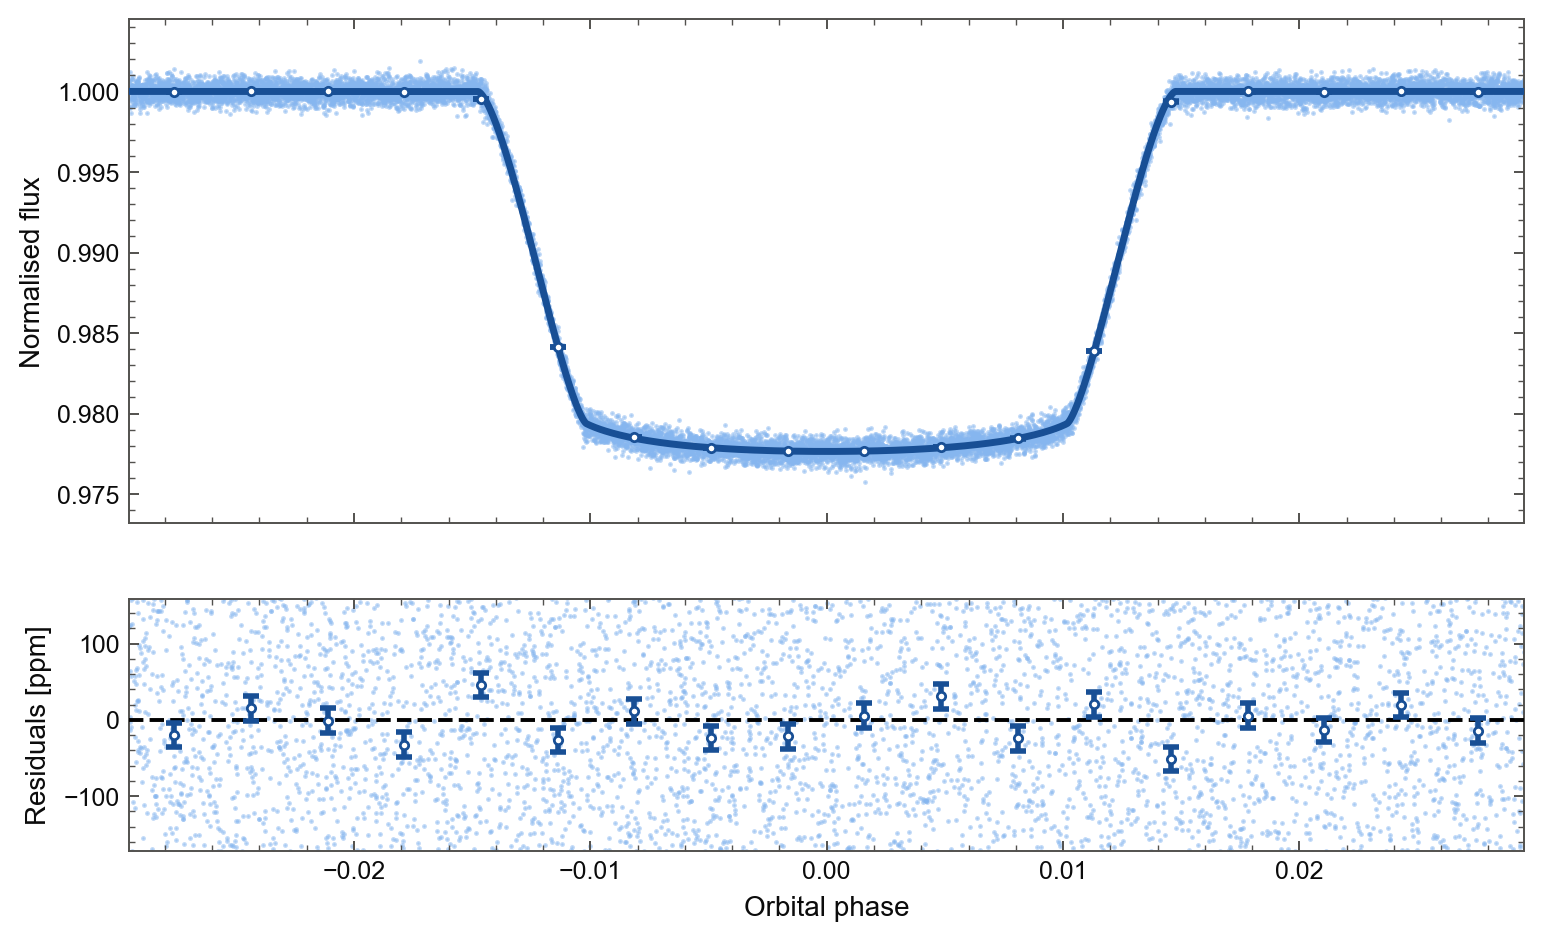

In [23]:
p = fit.plots()
p.phase_folded_lc();

| Parameter | jstark | ERS benchmark |
| --- | --- | --- |
| $t_0$ (BJD_TDB) | 2459771.335679 ± 0.000008 | 2459771.335647 |
| $a/R_*$ | 11.419 ± 0.013 | 11.390 |
| $b$ | 0.4448 ± 0.0027 | 0.4498 |
| $R_p/R_*$ | 0.14617 ± 0.00009 | |

The geometry agrees with the benchmark within about 2σ (the benchmark orbit
is a joint fit of all JWST, TESS and ground-based data). The residuals are
1.05 times the propagated errors, and bin down nearly as white noise.

## 7. Transmission spectrum

`SpectroscopicFit` fits one light curve per wavelength bin, here the 147
bins of the ERS benchmark. The orbit and the ramp timescale are fixed to the
white-light medians (`channel_priors`); every bin has its own $R_p/R_*$,
limb darkening and systematics. The 145 bins took 1.9 hours with 12
processes.

In [24]:
Z = os.path.join(FULL, 'comparison', 'published', 'ZENODO', '4_TRANSMISSION_SPECTRA',
                 'Fit_LimbDarkening')
ers = Table.read(os.path.join(Z, 'NIRSpec_PRISM', 'bins_scale1.csv'))
spec_dir = os.path.join(FULL, 'fits', 'spec_ers147')
if RUN_FULL:
    lc = LightCurves.from_spectra(spec.fname, name='PRISM').exclude(ints=[(20750, 20766)])
    pri = fit.channel_priors(fix=('P', 't0', 'a', 'b', 'ecc', 'omega', 'ramptau'))
    pri.update({'p_p1': ('uniform', [0.05, 0.25]),
                'q1_PRISM': ('uniform', [0., 1.]), 'q2_PRISM': ('uniform', [0., 1.])})
    edges = np.stack([ers['wave_low'], ers['wave_hig']], axis=1)
    sf = SpectroscopicFit({'PRISM': lc}, priors=pri, out_folder=spec_dir, edges=edges,
                          linear=['time', 'dy'], ramp=1)
    sf.run(nproc=12)
tsp = Spectrum.read(os.path.join(spec_dir, 'spectrum.ecsv'))
print(len(tsp), 'bins')

145 bins


unsaturated bins: median jstark - ERS = -152 ppm, scatter after the offset 90 ppm, error ratio 1.14


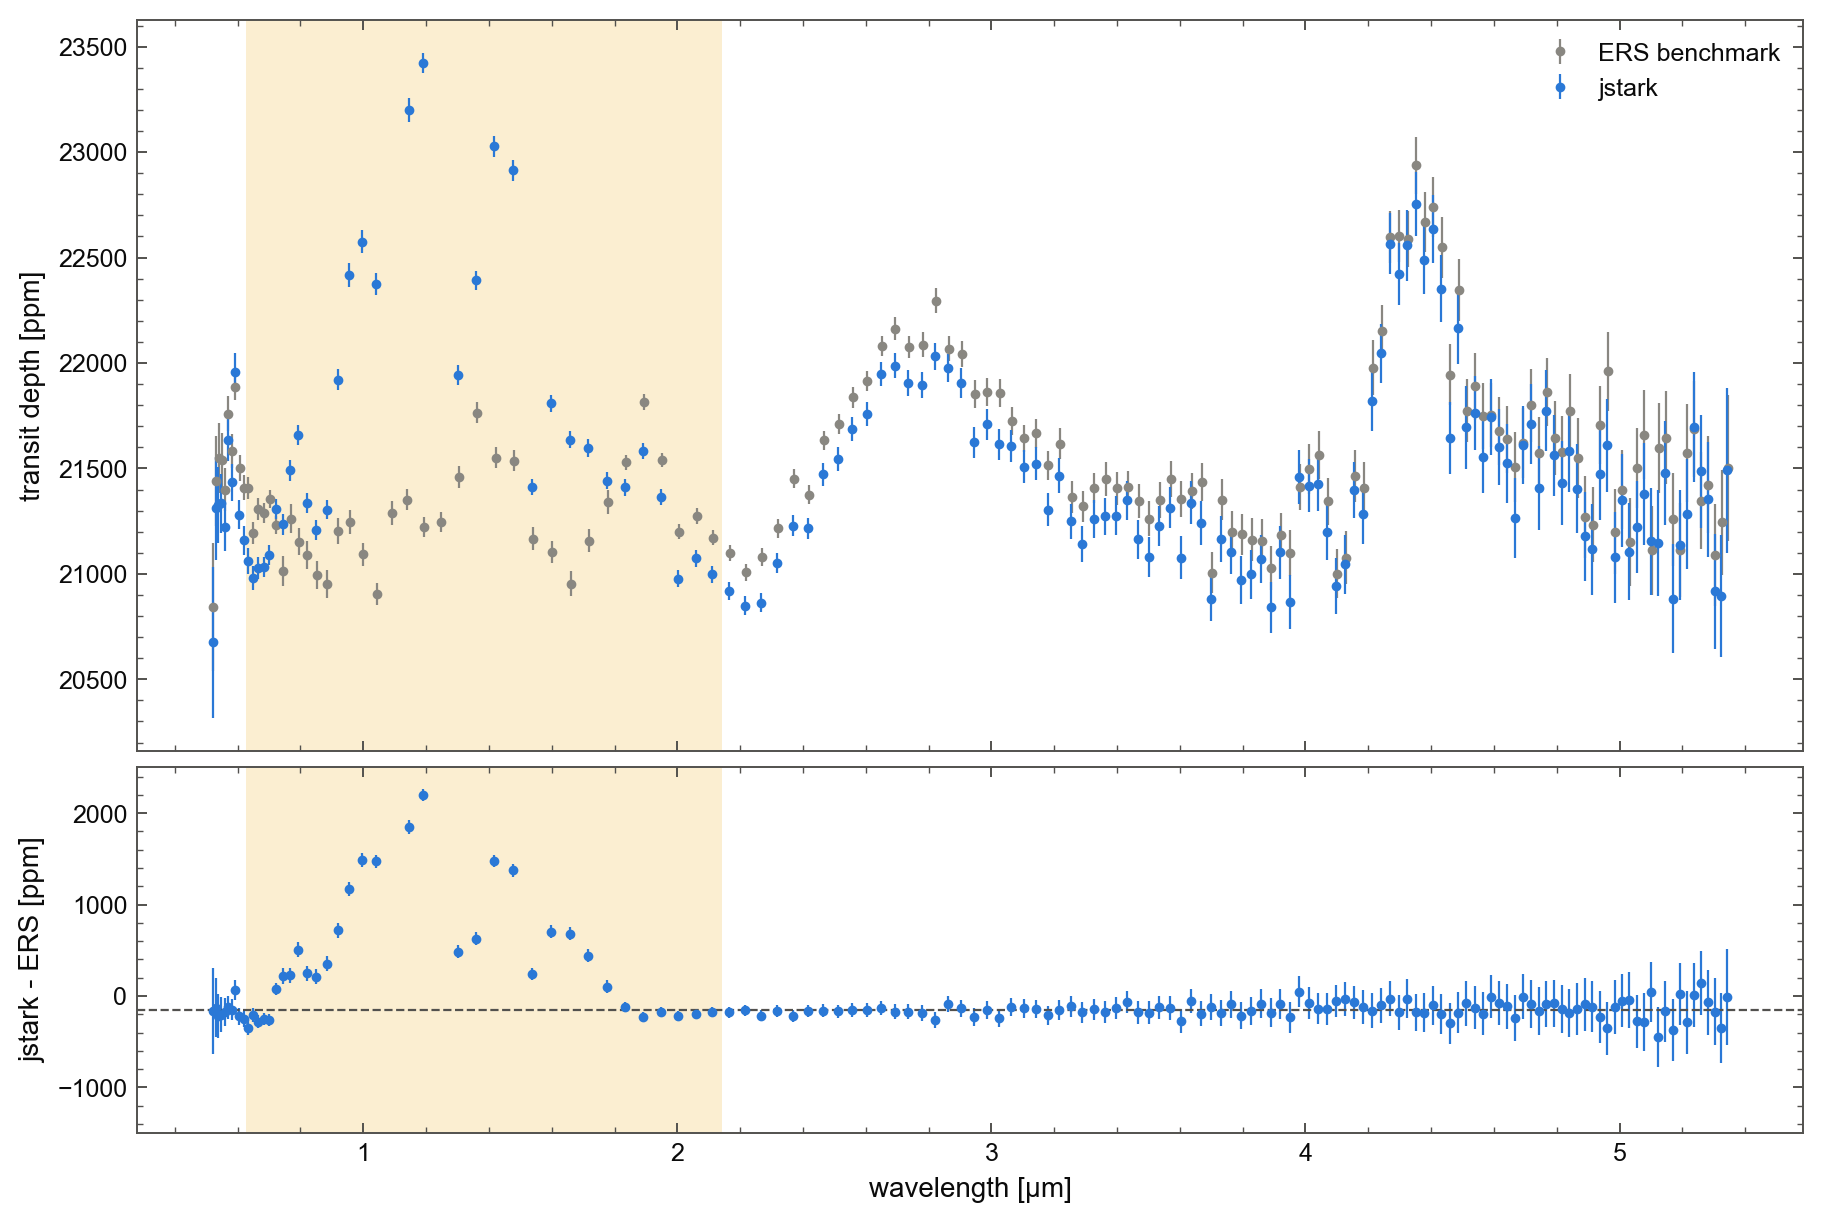

In [25]:
def depth(t):
    p = np.asarray(t['rp/rs'])
    return p ** 2 * 1e6, p * np.asarray(t['rp/rs_err_low'] + t['rp/rs_err_hih']) * 1e6

ers_d, ers_e = depth(ers)
sat = np.asarray(ers['satflag']) > 0          # bins flagged as saturated by ERS
b = np.asarray(tsp['bin'])
d = np.asarray(tsp['depth_p1_ppm'])
e = 0.5 * np.asarray(tsp['depth_p1_ppm_errp'] + tsp['depth_p1_ppm_errm'])
diff = d - ers_d[b]
off = np.median(diff[~sat[b]])
print(f'unsaturated bins: median jstark - ERS = {off:.0f} ppm, '
      f'scatter after the offset {np.std(diff[~sat[b]] - off):.0f} ppm, '
      f'error ratio {np.median(e[~sat[b]] / ers_e[b][~sat[b]]):.2f}')

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout='constrained',
                             gridspec_kw=dict(height_ratios=[2, 1]))
a1.errorbar(ers['wave'], ers_d, ers_e, fmt='o', color='#898781', ms=2.5, elinewidth=0.8, label='ERS benchmark')
a1.errorbar(tsp['wave'], d, e, fmt='o', color='C0', ms=2.5, elinewidth=0.8, label='jstark')
a2.errorbar(tsp['wave'], diff, np.hypot(e, ers_e[b]), fmt='o', color='C0', ms=2.5, elinewidth=0.8)
a2.axhline(off, color='#52514e', lw=0.8, ls='--')
for a in (a1, a2):
    for k in np.flatnonzero(sat):
        a.axvspan(ers['wave_low'][k], ers['wave_hig'][k], color='#eda100', alpha=0.18, lw=0)
a1.set_ylabel('transit depth [ppm]'); a1.legend(loc='upper right')
a2.set_ylabel('jstark - ERS [ppm]'); a2.set_xlabel('wavelength [µm]')
fig.align_ylabels((a1, a2))
a2.set_ylim(-1500, 2500);

Outside the saturated region (shaded) the two spectra have the same shape:
the differences scatter by about 90 ppm around a constant offset, and no
bin differs by more than 3σ. Two differences need explaining.

**The offset of −150 ppm.** Independent reductions of the same data differ
by offsets of this size. The ERS benchmark light curves are exactly those of
the FIREFLy reduction of Rustamkulov et al. (2023). Compared with all four
published reductions of this transit, in the same bins, jstark agrees with
tshirt to within 4-22 ppm at 2.1-5.0 µm, while the published reductions
themselves span about 340 ppm at 4.4-5.0 µm (Tiberius shallowest, Eureka!
deepest). About 76 ppm of the offset comes from modelling the ramp instead
of discarding the first 2000 integrations, and about 24 ppm from the orbit.
Wider apertures give shallower depths in the red (the PSF wings transit less
deeply than the core), a plausible reason for the spread between
reductions.

**The 14% larger errors** are the cost of fitting the ramp instead of
trimming. Refitting bins with the first 2000 integrations removed and no
ramp gives errors 0.98-1.02 times the benchmark's.

### 7.1 The saturated region

In the saturated bins the default extraction is biased deep, by up to
+1500 ppm near 1 µm, with a saw-tooth that follows exactly the number of
usable groups of the core. The reason is the brighter-fatter effect: during
the transit the PSF narrows and charge moves from the wings back into the
core, so the wings transit *more* deeply than the core (in one column: core
21,200 ppm, neighbours 28,700 ppm). A plain column sum is immune. Optimal
weights are not: where the core keeps fewer groups, its variance is larger
and the weights shift towards the wings.

The option `ex.set('extract', saturated_box=True)` uses the box sum in every
column whose aperture holds a saturating pixel and keeps the optimal
weights elsewhere. To judge which depths are right, the spectra are compared
with the NIRISS/SOSS spectrum of the same planet (also from the ERS
benchmark), which does not saturate. Each spectrum gets its own offset to
SOSS from the unsaturated bins both cover.

ERS benchmark          33 saturated bins: mean PRISM - SOSS =  -220 ppm, reduced chi2  15.9
jstark default         33 saturated bins: mean PRISM - SOSS =  +391 ppm, reduced chi2 160.8
jstark saturated_box   33 saturated bins: mean PRISM - SOSS =   -48 ppm, reduced chi2  12.8


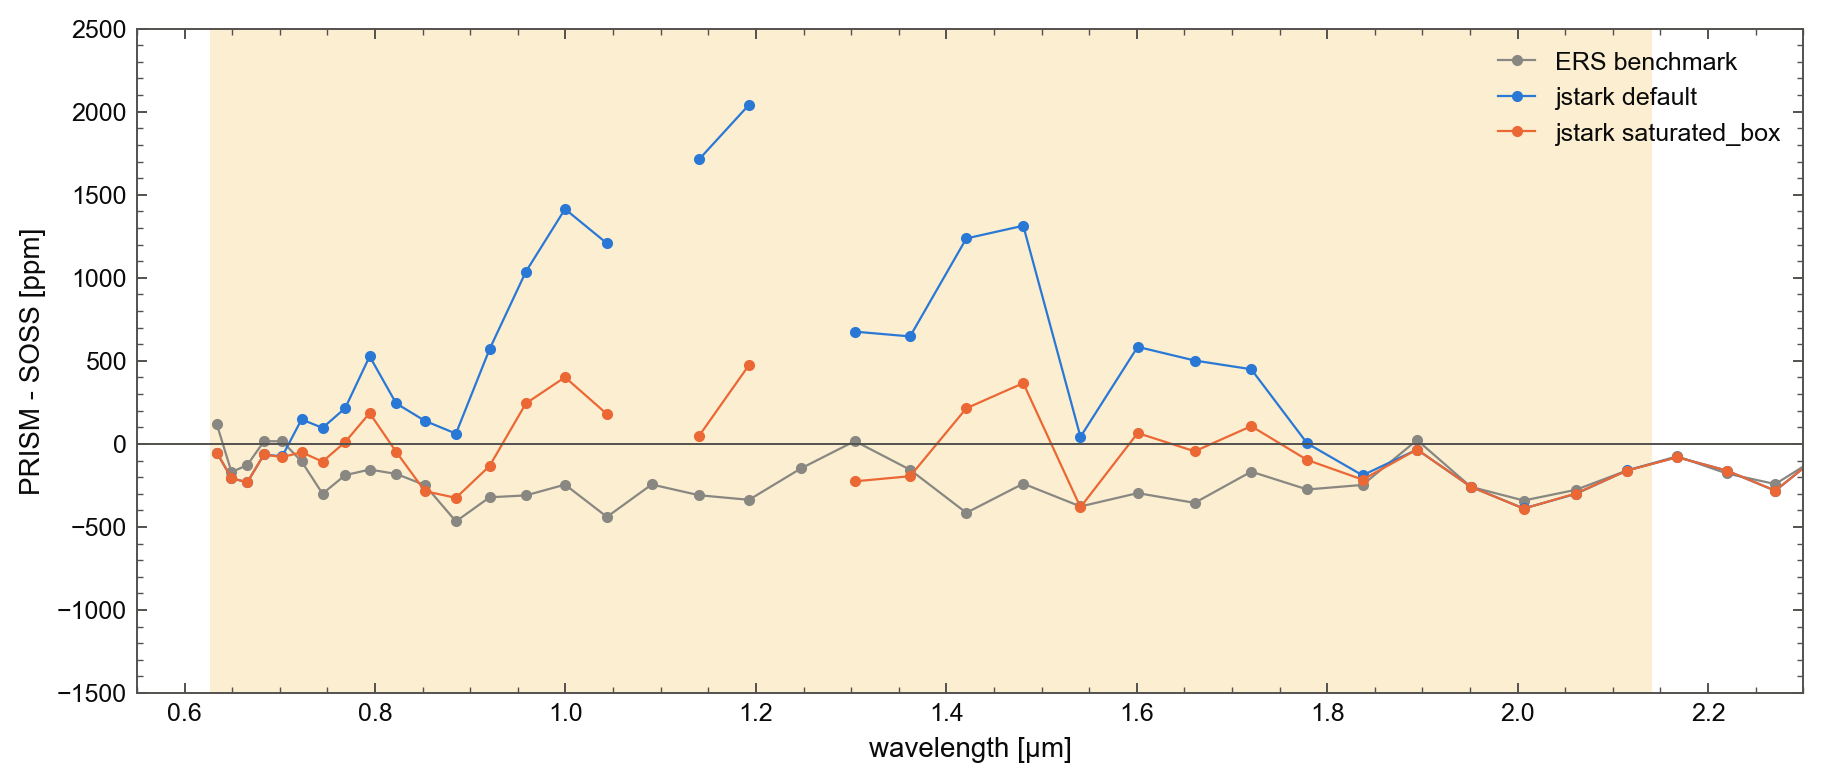

In [26]:
def soss_on(lo, hi):
    '''SOSS benchmark depths, inverse-variance averaged onto the PRISM bins
    (order 2 below 0.85 micron, order 1 above).'''
    o2, o1 = (Table.read(os.path.join(Z, f'NIRISS_SOSS_Order{k}', 'bins_scale1.csv')) for k in (2, 1))
    k2 = np.asarray(o2['wave']) < 0.85
    wv = np.r_[np.asarray(o2['wave'])[k2], o1['wave']]
    dd, ee = (np.r_[x[k2], y] for x, y in zip(depth(o2), depth(o1)))
    out, err = np.full(len(lo), np.nan), np.full(len(lo), np.nan)
    for k, (a, b_) in enumerate(zip(lo, hi)):
        m = (wv >= a) & (wv < b_) & np.isfinite(dd)
        if m.any():
            iv = 1 / ee[m] ** 2
            out[k], err[k] = np.sum(iv * dd[m]) / iv.sum(), iv.sum() ** -0.5
    return out, err

lo, hi, pw = (np.asarray(ers[k]) for k in ('wave_low', 'wave_hig', 'wave'))
soss, soss_e = soss_on(lo, hi)
# fewest usable groups of any column in each bin (from the extraction's SATGRP)
lam_f, sg_f = spec.wavelength[1], spec.satgrp[1]
bin_sg = np.array([sg_f[(lam_f >= a) & (lam_f < b_)].min() if ((lam_f >= a) & (lam_f < b_)).any() else -1
                   for a, b_ in zip(lo, hi)])
ng = spec.ngroups or int(sg_f.max())

def on_ers_bins(t):
    dd, ee = np.full(len(ers), np.nan), np.full(len(ers), np.nan)
    bb = np.asarray(t['bin'])
    dd[bb] = t['depth_p1_ppm']
    ee[bb] = 0.5 * np.asarray(t['depth_p1_ppm_errp'] + t['depth_p1_ppm_errm'])
    return dd, ee

satbox = Spectrum.read(os.path.join(FULL, 'fits', 'spec_satbox', 'spectrum.ecsv'))
variants = {'ERS benchmark': (ers_d, ers_e), 'jstark default': on_ers_bins(tsp),
            'jstark saturated_box': on_ers_bins(satbox)}

# reference bins: unsaturated, covered by SOSS; each spectrum gets its own offset there
ref = np.isfinite(soss) & ~sat & (bin_sg == ng) & (pw < 2.8)
common = np.all([np.isfinite(dd) for dd, _ in variants.values()], axis=0)   # bins in every spectrum
fig, ax = plt.subplots(figsize=(9, 3.8), layout='constrained')
for (name, (dd, ee)), col in zip(variants.items(), ('#898781', 'C0', 'C1')):
    r, tot = dd - soss, np.hypot(ee, soss_e)
    m = ref & np.isfinite(r)
    r = r - np.sum(r[m] / tot[m] ** 2) / np.sum(1 / tot[m] ** 2)
    ms = sat & np.isfinite(r) & common
    print(f'{name:22s} {ms.sum()} saturated bins: mean PRISM - SOSS = {np.mean(r[ms]):+5.0f} ppm, '
          f'reduced chi2 {np.mean((r[ms] / tot[ms]) ** 2):5.1f}')
    ax.plot(pw, r, 'o-', ms=3, lw=0.8, color=col, label=name)
ax.axhline(0, color='#52514e', lw=0.7)
for k in np.flatnonzero(sat):
    ax.axvspan(lo[k], hi[k], color='#eda100', alpha=0.18, lw=0)
ax.set_xlim(0.55, 2.3); ax.set_ylim(-1500, 2500)
ax.set_xlabel('wavelength [µm]'); ax.set_ylabel('PRISM - SOSS [ppm]')
ax.legend();

<div class="alert alert-info">

**Why saturated_box is an option and not (yet) the default**

Against SOSS, the mean bias of the 33 saturated bins is +391 ppm with the
default, −219 ppm for the ERS benchmark and **−48 ppm with
`saturated_box`**, with a reduced χ² of 12.8 (ERS 15.6, default 161) and no
larger errors. Two other fixes were tried and dropped: flagging whole
columns at their first saturated group, as the published reductions do,
biased the depths *shallow* (−359 ppm; this reproduces the dilution of the
benchmark spectrum), and modelling the width change `ds` in the profile
removed only part of the bias and moved the unsaturated bins.

It has been tested on one data set only, so it stays an option until it is
confirmed on a second saturated PRISM observation. For saturated PRISM data
we recommend `saturated_box=True`, and checking `SATGRP_O1` before
interpreting the 0.7-1.9 µm depths.

</div>

## 8. Summary of the defaults

| Stage | Default (NIRSpec) | Evidence |
| --- | --- | --- |
| Stage 1 | `consistent_saturation` from all segments | switching pixels scattered 2.5-3.7 × their errors; 1.2 × with it |
| Stage 1 | `n_pix_grow_sat=1`; `SATURATED` not treated as bad | neighbours 2.5-3 × too bright without growth; 270 → 18 replaced pixels |
| Stage 1 | `group_bkg`: column median at the group level | white light 715 → 177 ppm (G395H) |
| Stage 1 | `temporal_jump`, leave-one-out, repair for < 10 groups | false flags 105 → 8 |
| Cleaning | exposure-wide noise and hot-pixel maps | false cosmic-ray flags 323 → 5 |
| Extraction | spline PSF with phase cross-validation | 175 ± 1 ppm for every knot setting (G395H) |
| Extraction | pixel-response map Q, temporal rejection | optimal extraction beats the box sum |
| Extraction | `min_groups=2` | group-0-only columns biased by ~7000 ppm |
| Extraction | `saturated_box` (option) | saturated bins +391 → −48 ppm against SOSS |
| Fitting | linear in time + `dy` + ramp; never `ds` or `dx` | `ds` follows the transit (brighter-fatter) |

The result: a PRISM spectrum that matches the published reductions in
shape and noise, with an absolute level within the spread of the published
reductions.